<a href="https://colab.research.google.com/github/yashvityagi/fetal-ultrasound-segmentation/blob/main/segmentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!unzip "/content/drive/MyDrive/8265464.zip" -d /content/dataset

Archive:  /content/drive/MyDrive/8265464.zip
 extracting: /content/dataset/Trans-ventricular.zip  
 extracting: /content/dataset/Diverse Fetal Head Images-orginal-image.zip  
 extracting: /content/dataset/Diverse Fetal Head Images.zip  
 extracting: /content/dataset/Readme.txt  
 extracting: /content/dataset/Trans-cerebellum-orginal-size.zip  
 extracting: /content/dataset/Trans-cerebellum.zip  
 extracting: /content/dataset/Trans-thalamic-orginal-size.zip  
 extracting: /content/dataset/Trans-thalamic.zip  
 extracting: /content/dataset/Trans-ventricular-orginal-size.zip  


In [ ]:
!ls -R /content/dataset/

/content/dataset/:
'Diverse Fetal Head Images-orginal-image.zip'
'Diverse Fetal Head Images.zip'
 Readme.txt
 Trans-cerebellum-orginal-size.zip
 Trans-cerebellum.zip
 Trans-thalamic-orginal-size.zip
 Trans-thalamic.zip
 Trans-ventricular-orginal-size.zip
 Trans-ventricular.zip


In [ ]:
import os
import zipfile

dataset_path = '/content/dataset/'

# Ensure the dataset directory exists
os.makedirs(dataset_path, exist_ok=True)

# List all items in the dataset directory
items = os.listdir(dataset_path)

# Filter for zip files
zip_files = [item for item in items if item.endswith('.zip')]

print(f"Found {len(zip_files)} zip files to extract:")
for zip_file_name in zip_files:
    print(f"- {zip_file_name}")

# Unzip each file into a new directory with the same name as the zip file (without .zip)
for zip_file_name in zip_files:
    full_zip_path = os.path.join(dataset_path, zip_file_name)

    # Create a directory for the extracted contents
    extract_dir_name = os.path.splitext(zip_file_name)[0] # Remove .zip extension
    extract_path = os.path.join(dataset_path, extract_dir_name)

    os.makedirs(extract_path, exist_ok=True)

    print(f"\nExtracting '{zip_file_name}' to '{extract_path}'...")
    with zipfile.ZipFile(full_zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_path)
    print("Extraction complete.")

# Optionally, list the contents of the dataset directory again to see the new folders
print("\nUpdated contents of /content/dataset/:")
!ls -F /content/dataset/

Found 8 zip files to extract:
- Trans-thalamic.zip
- Trans-cerebellum.zip
- Trans-ventricular-orginal-size.zip
- Trans-ventricular.zip
- Trans-cerebellum-orginal-size.zip
- Diverse Fetal Head Images.zip
- Diverse Fetal Head Images-orginal-image.zip
- Trans-thalamic-orginal-size.zip

Extracting 'Trans-thalamic.zip' to '/content/dataset/Trans-thalamic'...
Extraction complete.

Extracting 'Trans-cerebellum.zip' to '/content/dataset/Trans-cerebellum'...
Extraction complete.

Extracting 'Trans-ventricular-orginal-size.zip' to '/content/dataset/Trans-ventricular-orginal-size'...
Extraction complete.

Extracting 'Trans-ventricular.zip' to '/content/dataset/Trans-ventricular'...
Extraction complete.

Extracting 'Trans-cerebellum-orginal-size.zip' to '/content/dataset/Trans-cerebellum-orginal-size'...
Extraction complete.

Extracting 'Diverse Fetal Head Images.zip' to '/content/dataset/Diverse Fetal Head Images'...
Extraction complete.

Extracting 'Diverse Fetal Head Images-orginal-image.zip' t

In [ ]:
import os

root_directory = '/content/dataset/'

print(f"Counting files in subfolders of: {root_directory}\n")

file_counts = {}
for dirpath, dirnames, filenames in os.walk(root_directory):
    # Exclude the root directory itself if we only want subfolders
    if dirpath == root_directory:
        continue

    # Count files only in actual subdirectories, not in the root directory if it contains files directly
    if filenames:
        relative_path = os.path.relpath(dirpath, root_directory)
        file_counts[relative_path] = len(filenames)

for folder, count in file_counts.items():
    print(f"Folder '{folder}': {count} files")

total_files = sum(file_counts.values())
print(f"\nTotal files in all extracted subfolders: {total_files}")

Counting files in subfolders of: /content/dataset/

Folder 'Trans-ventricular-orginal-size/Trans-ventricular-orginal-size': 597 files
Folder 'Trans-thalamic/Trans-thalamic': 12 files
Folder 'Trans-thalamic/Trans-thalamic/Trans-thalamic': 1565 files
Folder 'Trans-cerebellum-orginal-size/Trans-cerebellum-orginal-size': 714 files
Folder 'Trans-ventricular/Trans-ventricular': 12 files
Folder 'Trans-ventricular/Trans-ventricular/Trans-ventricular': 584 files
Folder 'Trans-thalamic-orginal-size/Trans-thalamic-orginal-size': 1638 files
Folder 'Trans-cerebellum/Trans-cerebellum': 12 files
Folder 'Trans-cerebellum/Trans-cerebellum/Trans-cerebellum': 684 files
Folder 'Diverse Fetal Head Images-orginal-image/Diverse Fetal Head Images-orginal-image': 999 files
Folder 'Diverse Fetal Head Images/Diverse Fetal Head Images': 11 files
Folder 'Diverse Fetal Head Images/Diverse Fetal Head Images/Orginal_train_images_to_959_661': 999 files

Total files in all extracted subfolders: 7827


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras import Model
from tensorflow.keras.applications import ResNet50V2 # Example for potential pre-trained encoder

import numpy as np
import matplotlib.pyplot as plt

print(f"TensorFlow Version: {tf.__version__}")

TensorFlow Version: 2.20.0


In [ ]:
def conv_block(input_tensor, num_filters):
    x = layers.Conv2D(num_filters, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(input_tensor)
    x = layers.Conv2D(num_filters, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(x)
    return x

def attention_gate(g, x, num_filters):
    # Gating signal (g) processing
    g1 = layers.Conv2D(num_filters, (1, 1), padding='same', use_bias=False)(g)

    # Feature map (x) processing
    x1 = layers.Conv2D(num_filters, (1, 1), padding='same', use_bias=False)(x)

    # Combine and apply activation
    psi = layers.Activation('relu')(layers.Add()([g1, x1]))
    psi = layers.Conv2D(1, (1, 1), padding='same', use_bias=False)(psi)
    psi = layers.Activation('sigmoid')(psi)

    # Apply attention to feature map
    return layers.Multiply()([x, psi])

In [ ]:
def build_double_unet_ag(input_shape=(256, 256, 3), num_classes=1):
    inputs = layers.Input(input_shape)

    # --- Encoder 1 (First U-Net) ---
    # Downsampling Path 1
    c1 = conv_block(inputs, 64)
    p1 = layers.MaxPooling2D((2, 2))(c1)

    c2 = conv_block(p1, 128)
    p2 = layers.MaxPooling2D((2, 2))(c2)

    c3 = conv_block(p2, 256)
    p3 = layers.MaxPooling2D((2, 2))(c3)

    c4 = conv_block(p3, 512)
    p4 = layers.MaxPooling2D((2, 2))(c4)

    # Bottleneck 1
    c5 = conv_block(p4, 1024)

    # Upsampling Path 1 (Decoder 1)
    up6 = layers.Conv2DTranspose(512, (2, 2), strides=(2, 2), padding='same')(c5)
    attn6 = attention_gate(g=up6, x=c4, num_filters=512)
    u6 = layers.concatenate([up6, attn6])
    c6 = conv_block(u6, 512)

    up7 = layers.Conv2DTranspose(256, (2, 2), strides=(2, 2), padding='same')(c6)
    attn7 = attention_gate(g=up7, x=c3, num_filters=256)
    u7 = layers.concatenate([up7, attn7])
    c7 = conv_block(u7, 256)

    up8 = layers.Conv2DTranspose(128, (2, 2), strides=(2, 2), padding='same')(c7)
    attn8 = attention_gate(g=up8, x=c2, num_filters=128)
    u8 = layers.concatenate([up8, attn8])
    c8 = conv_block(u8, 128)

    up9 = layers.Conv2DTranspose(64, (2, 2), strides=(2, 2), padding='same')(c8)
    attn9 = attention_gate(g=up9, x=c1, num_filters=64)
    u9 = layers.concatenate([up9, attn9])
    c9 = conv_block(u9, 64)

    # Output of the first U-Net
    output1 = layers.Conv2D(num_classes, (1, 1), activation='sigmoid', padding='same', name='output_unet1')(c9)

    # --- Guided Decoder (Connecting U-Net 1 to U-Net 2) ---
    # Concatenate original input with output of U-Net 1 to guide the second U-Net
    # Ensure output1 has the same spatial dimensions as inputs
    guided_input = layers.concatenate([inputs, output1])

    # --- Encoder 2 (Second U-Net) ---
    # Downsampling Path 2
    d1 = conv_block(guided_input, 64)
    dp1 = layers.MaxPooling2D((2, 2))(d1)

    d2 = conv_block(dp1, 128)
    dp2 = layers.MaxPooling2D((2, 2))(d2)

    d3 = conv_block(dp2, 256)
    dp3 = layers.MaxPooling2D((2, 2))(d3)

    d4 = conv_block(dp3, 512)
    dp4 = layers.MaxPooling2D((2, 2))(d4)

    # Bottleneck 2
    d5 = conv_block(dp4, 1024)

    # Upsampling Path 2 (Decoder 2)
    dup6 = layers.Conv2DTranspose(512, (2, 2), strides=(2, 2), padding='same')(d5)
    dattn6 = attention_gate(g=dup6, x=d4, num_filters=512)
    du6 = layers.concatenate([dup6, dattn6])
    dc6 = conv_block(du6, 512)

    dup7 = layers.Conv2DTranspose(256, (2, 2), strides=(2, 2), padding='same')(dc6)
    dattn7 = attention_gate(g=dup7, x=d3, num_filters=256)
    du7 = layers.concatenate([dup7, dattn7])
    dc7 = conv_block(du7, 256)

    dup8 = layers.Conv2DTranspose(128, (2, 2), strides=(2, 2), padding='same')(dc7)
    dattn8 = attention_gate(g=dup8, x=d2, num_filters=128)
    du8 = layers.concatenate([dup8, dattn8])
    dc8 = conv_block(du8, 128)

    dup9 = layers.Conv2DTranspose(64, (2, 2), strides=(2, 2), padding='same')(dc8)
    dattn9 = attention_gate(g=dup9, x=d1, num_filters=64)
    du9 = layers.concatenate([dup9, dattn9])
    dc9 = conv_block(du9, 64)

    # Final output
    outputs = layers.Conv2D(num_classes, (1, 1), activation='sigmoid', padding='same', name='final_output')(dc9)

    model = Model(inputs=[inputs], outputs=[outputs, output1]) # Return both outputs for potential multi-task learning
    return model

In [ ]:
# Example usage:
model = build_double_unet_ag(input_shape=(256, 256, 3), num_classes=1) # For binary segmentation
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 256, 256,  │      1,792 │ input_layer[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 256, 256,  │     36,928 │ conv2d[0][0]      │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 128, 128,  │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 128, 128,  │     73,856 │ max_pooling2d[0]… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 128, 128,  │    147,584 │ conv2d_2[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 64, 64,    │          0 │ conv2d_3[0][0]    │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 64, 64,    │    295,168 │ max_pooling2d_1[… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 64, 64,    │    590,080 │ conv2d_4[0][0]    │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 32, 32,    │          0 │ conv2d_5[0][0]    │
│ (MaxPooling2D)      │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 32, 32,    │  1,180,160 │ max_pooling2d_2[… │
│                     │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 32, 32,    │  2,359,808 │ conv2d_6[0][0]    │
│                     │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 16, 16,    │          0 │ conv2d_7[0][0]    │
│ (MaxPooling2D)      │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 16, 16,    │  4,719,616 │ max_pooling2d_3[… │
│                     │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 16, 16,    │  9,438,208 │ conv2d_8[0][0]    │
│                     │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose    │ (None, 32, 32,    │  2,097,664 │ conv2d_9[0][0]    │
│ (Conv2DTranspose)   │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_10 (Conv2D)  │ (None, 32, 32,    │    262,144 │ conv2d_transpose

 Total params: 63,458,626 (242.08 MB)

 Trainable params: 63,458,626 (242.08 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
import numpy as np
from tensorflow.keras.utils import Sequence
from tensorflow.keras.preprocessing.image import load_img, img_to_array
import os

class CustomDataGenerator(Sequence):
    def __init__(self, image_filenames, mask_filenames, batch_size, target_size=(256, 256), num_classes=1, augment=False):
        self.image_filenames = image_filenames
        self.mask_filenames = mask_filenames
        self.batch_size = batch_size
        self.target_size = target_size
        self.num_classes = num_classes
        self.augment = augment
        self.on_epoch_end()

    def __len__(self):
        return int(np.floor(len(self.image_filenames) / self.batch_size))

    def __getitem__(self, index):
        # Generate indexes of the batch
        indexes = self.indexes[index * self.batch_size:(index + 1) * self.batch_size]

        # Find list of IDs
        batch_image_filenames = [self.image_filenames[k] for k in indexes]
        batch_mask_filenames = [self.mask_filenames[k] for k in indexes]

        # Generate data
        X, y = self.__data_generation(batch_image_filenames, batch_mask_filenames)
        return X, y

    def on_epoch_end(self):
        'Updates indexes after each epoch'
        self.indexes = np.arange(len(self.image_filenames))
        if self.augment: # Shuffle only if augmentation is active for randomness
            np.random.shuffle(self.indexes)

    def _load_image(self, image_path):
        # Load image and resize it to target_size
        img = load_img(image_path, target_size=self.target_size)
        img = img_to_array(img) / 255.0 # Normalize to [0, 1]
        return img

    def _load_mask(self, mask_path):
        # Load mask and resize it to target_size
        # Masks are typically grayscale and need to be binary or categorical
        mask = load_img(mask_path, target_size=self.target_size, color_mode='grayscale')
        mask = img_to_array(mask) / 255.0 # Normalize to [0, 1] for binary masks
        # For multi-class segmentation, you might need to convert to one-hot encoding here
        return mask

    def __data_generation(self, batch_image_filenames, batch_mask_filenames):
        # X is a batch of images, y is a batch of masks
        X = np.empty((self.batch_size, *self.target_size, 3)) # Assuming RGB images
        y_output1 = np.empty((self.batch_size, *self.target_size, self.num_classes)) # Output for UNet1
        y_final = np.empty((self.batch_size, *self.target_size, self.num_classes))   # Output for final UNet2

        # Generate data
        for i, (img_path, mask_path) in enumerate(zip(batch_image_filenames, batch_mask_filenames)):
            # Load and preprocess image
            img = self._load_image(img_path)
            X[i,] = img

            # Load and preprocess mask
            mask = self._load_mask(mask_path)
            y_output1[i,] = mask # Assuming both U-Nets predict the same mask type
            y_final[i,] = mask

        # If using multi-task learning, return a dictionary or list of outputs
        return X, {'output_unet1': y_output1, 'final_output': y_final}

    def _augment_data(self, image, mask):
        # Placeholder for data augmentation
        # You can add random flips, rotations, shifts, etc., here
        # Ensure image and mask are augmented consistently
        return image, mask

In [ ]:
!ls -F /content/dataset/Trans-thalamic/Trans-thalamic/

Trans-thalamic/			       Trans-thalamic-OpenImage-14-3-23.zip
Trans-thalamic-Cityscapes.zip	       Trans-thalamic-PASCAL.zip
Trans-thalamic-COCO.zip		       Trans-Thalamic-Pixel-Size.csv
Trans-thalamic-CVAT.zip		       Trans-thalamic-Segmentation.zip
Trans-thalamic-Datumaro.zip	       Trans-thalamic-TFRecord.zip
Trans-thalamic-ICDAR-Localization.zip  Trans-thalamic-YOLO.zip
Trans-thalamic-LabelMe.zip


In [ ]:
# Unzip the segmentation masks
segmentation_zip_path = '/content/dataset/Trans-thalamic/Trans-thalamic/Trans-thalamic-Segmentation.zip'
extract_segmentation_path = '/content/dataset/Trans-thalamic/Trans-thalamic/Trans-thalamic-Segmentation/'

print(f"Unzipping '{segmentation_zip_path}' to '{extract_segmentation_path}'...")
with zipfile.ZipFile(segmentation_zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_segmentation_path)
print("Extraction complete.")

# Now, let's list the contents of the newly extracted folder to confirm its structure
print(f"\nContents of {extract_segmentation_path}:")
!ls -F {extract_segmentation_path}

Unzipping '/content/dataset/Trans-thalamic/Trans-thalamic/Trans-thalamic-Segmentation.zip' to '/content/dataset/Trans-thalamic/Trans-thalamic/Trans-thalamic-Segmentation/'...
Extraction complete.

Contents of /content/dataset/Trans-thalamic/Trans-thalamic/Trans-thalamic-Segmentation/:
ImageSets/  labelmap.txt  SegmentationClass/  SegmentationObject/


In [ ]:
import os
from sklearn.model_selection import train_test_split


dataset_root = '/content/dataset/'

# Function to collect files from a directory
def collect_files(directory, extensions=('.png', '.jpg', '.jpeg')):
    files = []
    if not os.path.exists(directory):
        print(f"Warning: Directory not found: {directory}")
        return []
    for root, _, filenames in os.walk(directory):
        for filename in filenames:
            if filename.lower().endswith(extensions):
                files.append(os.path.join(root, filename))
    return sorted(files)



# Placeholder for image directory - replace with your actual image folder
image_dir = os.path.join(dataset_root, 'Trans-thalamic', 'Trans-thalamic') # Corrected image directory

mask_dir = os.path.join(dataset_root, 'Trans-thalamic', 'Trans-thalamic', 'Trans-thalamic-Segmentation', 'SegmentationClass') # Corrected mask directory

print(f"Attempting to collect images from: {image_dir}")
print(f"Attempting to collect masks from: {mask_dir}")

all_images = collect_files(image_dir)
all_masks = collect_files(mask_dir)


image_filenames = []
mask_filenames = []

# Create a dictionary of mask base names to their full paths for efficient lookup
mask_name_to_path = {os.path.basename(p): p for p in all_masks}

for img_path in all_images:
    img_base_name = os.path.basename(img_path)



    expected_mask_base_name = img_base_name # Default: assume same name, different folder

    if expected_mask_base_name in mask_name_to_path:
        image_filenames.append(img_path)
        mask_filenames.append(mask_name_to_path[expected_mask_base_name])
    else:
        # Optional: Print images for which no mask was found to debug
        # print(f"No matching mask found for image: {img_path}")
        pass

print(f"\nFound {len(image_filenames)} paired image files.")
print(f"Found {len(mask_filenames)} paired mask files.")

if not image_filenames or not mask_filenames:
    print("Error: No image-mask pairs found. Please check your `image_dir` and `mask_dir` and the pairing logic.")
    # To avoid errors in generator creation, we will use dummy lists if no files are found
    image_filenames = [os.path.join(dataset_root, 'dummy_image.png')]
    mask_filenames = [os.path.join(dataset_root, 'dummy_mask.png')]


# --- Split data into training and validation sets ---
# Using a fixed random state for reproducibility
train_images, val_images, train_masks, val_masks = train_test_split(
    image_filenames, mask_filenames, test_size=0.2, random_state=42
)

print(f"\nTraining samples: {len(train_images)}")
print(f"Validation samples: {len(val_images)}")


# Create an instance of the generator
batch_size = 8
target_size = (256, 256) # Must match model input_shape
num_classes = 1 # 1 for binary segmentation

# Create data generators
train_generator = CustomDataGenerator(train_images, train_masks, batch_size, target_size, num_classes, augment=True)
val_generator = CustomDataGenerator(val_images, val_masks, batch_size, target_size, num_classes, augment=False)

print(f"\nTrain Generator created with {len(train_generator)} batches.")
print(f"Validation Generator created with {len(val_generator)} batches.")

Attempting to collect images from: /content/dataset/Trans-thalamic/Trans-thalamic
Attempting to collect masks from: /content/dataset/Trans-thalamic/Trans-thalamic/Trans-thalamic-Segmentation/SegmentationClass

Found 4695 paired image files.
Found 4695 paired mask files.

Training samples: 3756
Validation samples: 939

Train Generator created with 469 batches.
Validation Generator created with 117 batches.


Model compiled successfully with AdamW, combined loss, and deep supervision!
Starting model training for 10 epochs...


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/10
156/156 ━━━━━━━━━━━━━━━━━━━━ 234s 1s/step - final_output_accuracy: 0.6536 - final_output_iou: 1.0000 - final_output_loss: 0.8851 - loss: 1.3285 - output_unet1_accuracy: 0.6541 - output_unet1_iou: 1.0000 - output_unet1_loss: 0.8869 - val_final_output_accuracy: 0.6483 - val_final_output_iou: 1.0000 - val_final_output_loss: 0.8860 - val_loss: 1.3289 - val_output_unet1_accuracy: 0.6485 - val_output_unet1_iou: 1.0000 - val_output_unet1_loss: 0.8857
Epoch 2/10
156/156 ━━━━━━━━━━━━━━━━━━━━ 197s 1s/step - final_output_accuracy: 0.6543 - final_output_iou: 1.0000 - final_output_loss: 0.8836 - loss: 1.3266 - output_unet1_accuracy: 0.6545 - output_unet1_iou: 1.0000 - output_unet1_loss: 0.8860 - val_final_output_accuracy: 0.6485 - val_final_output_iou: 1.0000 - val_final_output_loss: 0.8837 - val_loss: 1.3265 - val_output_unet1_accuracy: 0.6484 - val_output_unet1_iou: 1.0000 - val_output_unet1_loss: 0.8856
Epoch 3/10
156/156 ━━━━━━━━━━━━━━━━━━━━ 197s 1s/step - final_output_accuracy: 0.65

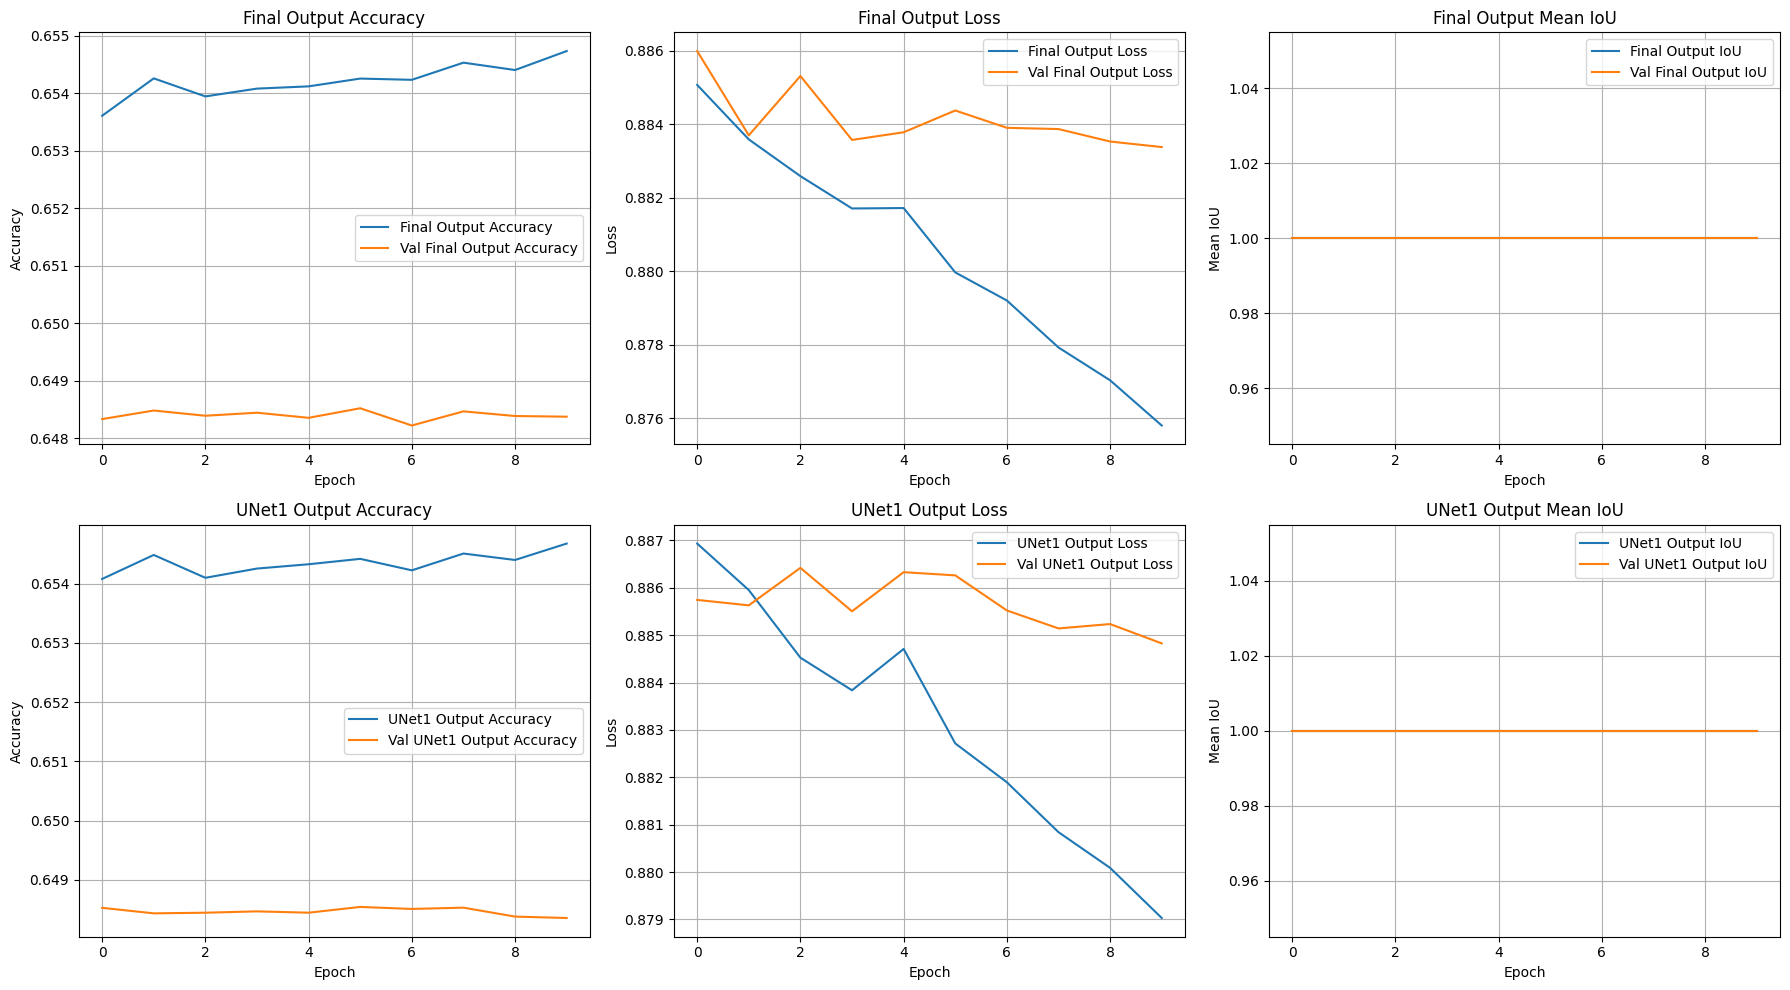

In [ ]:
import tensorflow as tf
from tensorflow.keras.optimizers import AdamW
from tensorflow.keras.losses import BinaryCrossentropy
from tensorflow.keras.metrics import MeanIoU
from tensorflow.keras import backend as K

# Custom Dice Loss function
def dice_loss(y_true, y_pred):
    y_true = tf.cast(y_true, tf.float32) # Ensure y_true is float32
    y_pred = tf.cast(y_pred, tf.float32) # Ensure y_pred is float32
    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(y_pred)
    intersection = K.sum(y_true_f * y_pred_f)
    return 1 - (2. * intersection + K.epsilon()) / (K.sum(y_true_f) + K.sum(y_pred_f) + K.epsilon())

# Combined Loss (Dice + Binary Crossentropy)
def combined_loss(y_true, y_pred):
    bce = BinaryCrossentropy()(y_true, y_pred)
    dice = dice_loss(y_true, y_pred)
    return bce + dice

# Compile the model
optimizer = AdamW(learning_rate=1e-4) # Changed to AdamW

# Define loss functions for each output
losses = {
    'final_output': combined_loss, # Using combined loss
    'output_unet1': combined_loss  # Using combined loss
}

# Assign loss weights for deep supervision, emphasizing the final output
loss_weights = {'final_output': 1.0, 'output_unet1': 0.5}

metrics = {
    'final_output': ['accuracy', MeanIoU(num_classes=2, name='iou')],
    'output_unet1': ['accuracy', MeanIoU(num_classes=2, name='iou')]
}

model.compile(optimizer=optimizer, loss=losses, loss_weights=loss_weights, metrics=metrics)

print("Model compiled successfully with AdamW, combined loss, and deep supervision!")

epochs = 10

print(f"Starting model training for {epochs} epochs...")

# Use the 'Trans-thalamic' generators from subclass_data_generators
trans_thalamic_train_gen = subclass_data_generators["Trans-thalamic"]["train_generator"]
trans_thalamic_val_gen = subclass_data_generators["Trans-thalamic"]["val_generator"]

history = model.fit(
    trans_thalamic_train_gen,
    epochs=epochs,
    validation_data=trans_thalamic_val_gen,
    verbose=1
)

print("Model training complete!")


import matplotlib.pyplot as plt

# Create a figure with 2 rows and 3 columns to display all metrics
plt.figure(figsize=(18, 10))

# Plotting Final Output Accuracy
plt.subplot(2, 3, 1) # 2 rows, 3 columns, 1st subplot
plt.plot(history.history['final_output_accuracy'], label='Final Output Accuracy')
plt.plot(history.history['val_final_output_accuracy'], label='Val Final Output Accuracy')
plt.title('Final Output Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend()
plt.grid(True)

# Plotting Final Output Loss
plt.subplot(2, 3, 2) # 2 rows, 3 columns, 2nd subplot
plt.plot(history.history['final_output_loss'], label='Final Output Loss')
plt.plot(history.history['val_final_output_loss'], label='Val Final Output Loss')
plt.title('Final Output Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend()
plt.grid(True)

# Plotting Final Output IoU
plt.subplot(2, 3, 3) # 2 rows, 3 columns, 3rd subplot
plt.plot(history.history['final_output_iou'], label='Final Output IoU')
plt.plot(history.history['val_final_output_iou'], label='Val Final Output IoU')
plt.title('Final Output Mean IoU')
plt.ylabel('Mean IoU')
plt.xlabel('Epoch')
plt.legend()
plt.grid(True)

# Plotting UNet1 Output Accuracy
plt.subplot(2, 3, 4) # 2 rows, 3 columns, 4th subplot
plt.plot(history.history['output_unet1_accuracy'], label='UNet1 Output Accuracy')
plt.plot(history.history['val_output_unet1_accuracy'], label='Val UNet1 Output Accuracy')
plt.title('UNet1 Output Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend()
plt.grid(True)

# Plotting UNet1 Output Loss
plt.subplot(2, 3, 5) # 2 rows, 3 columns, 5th subplot
plt.plot(history.history['output_unet1_loss'], label='UNet1 Output Loss')
plt.plot(history.history['val_output_unet1_loss'], label='Val UNet1 Output Loss')
plt.title('UNet1 Output Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend()
plt.grid(True)

# Plotting UNet1 Output IoU
plt.subplot(2, 3, 6) # 2 rows, 3 columns, 6th subplot
plt.plot(history.history['output_unet1_iou'], label='UNet1 Output IoU')
plt.plot(history.history['val_output_unet1_iou'], label='Val UNet1 Output IoU')
plt.title('UNet1 Output Mean IoU')
plt.ylabel('Mean IoU')
plt.xlabel('Epoch')
plt.legend()
plt.grid(True)

plt.tight_layout() # Adjust layout to prevent overlapping titles/labels
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step


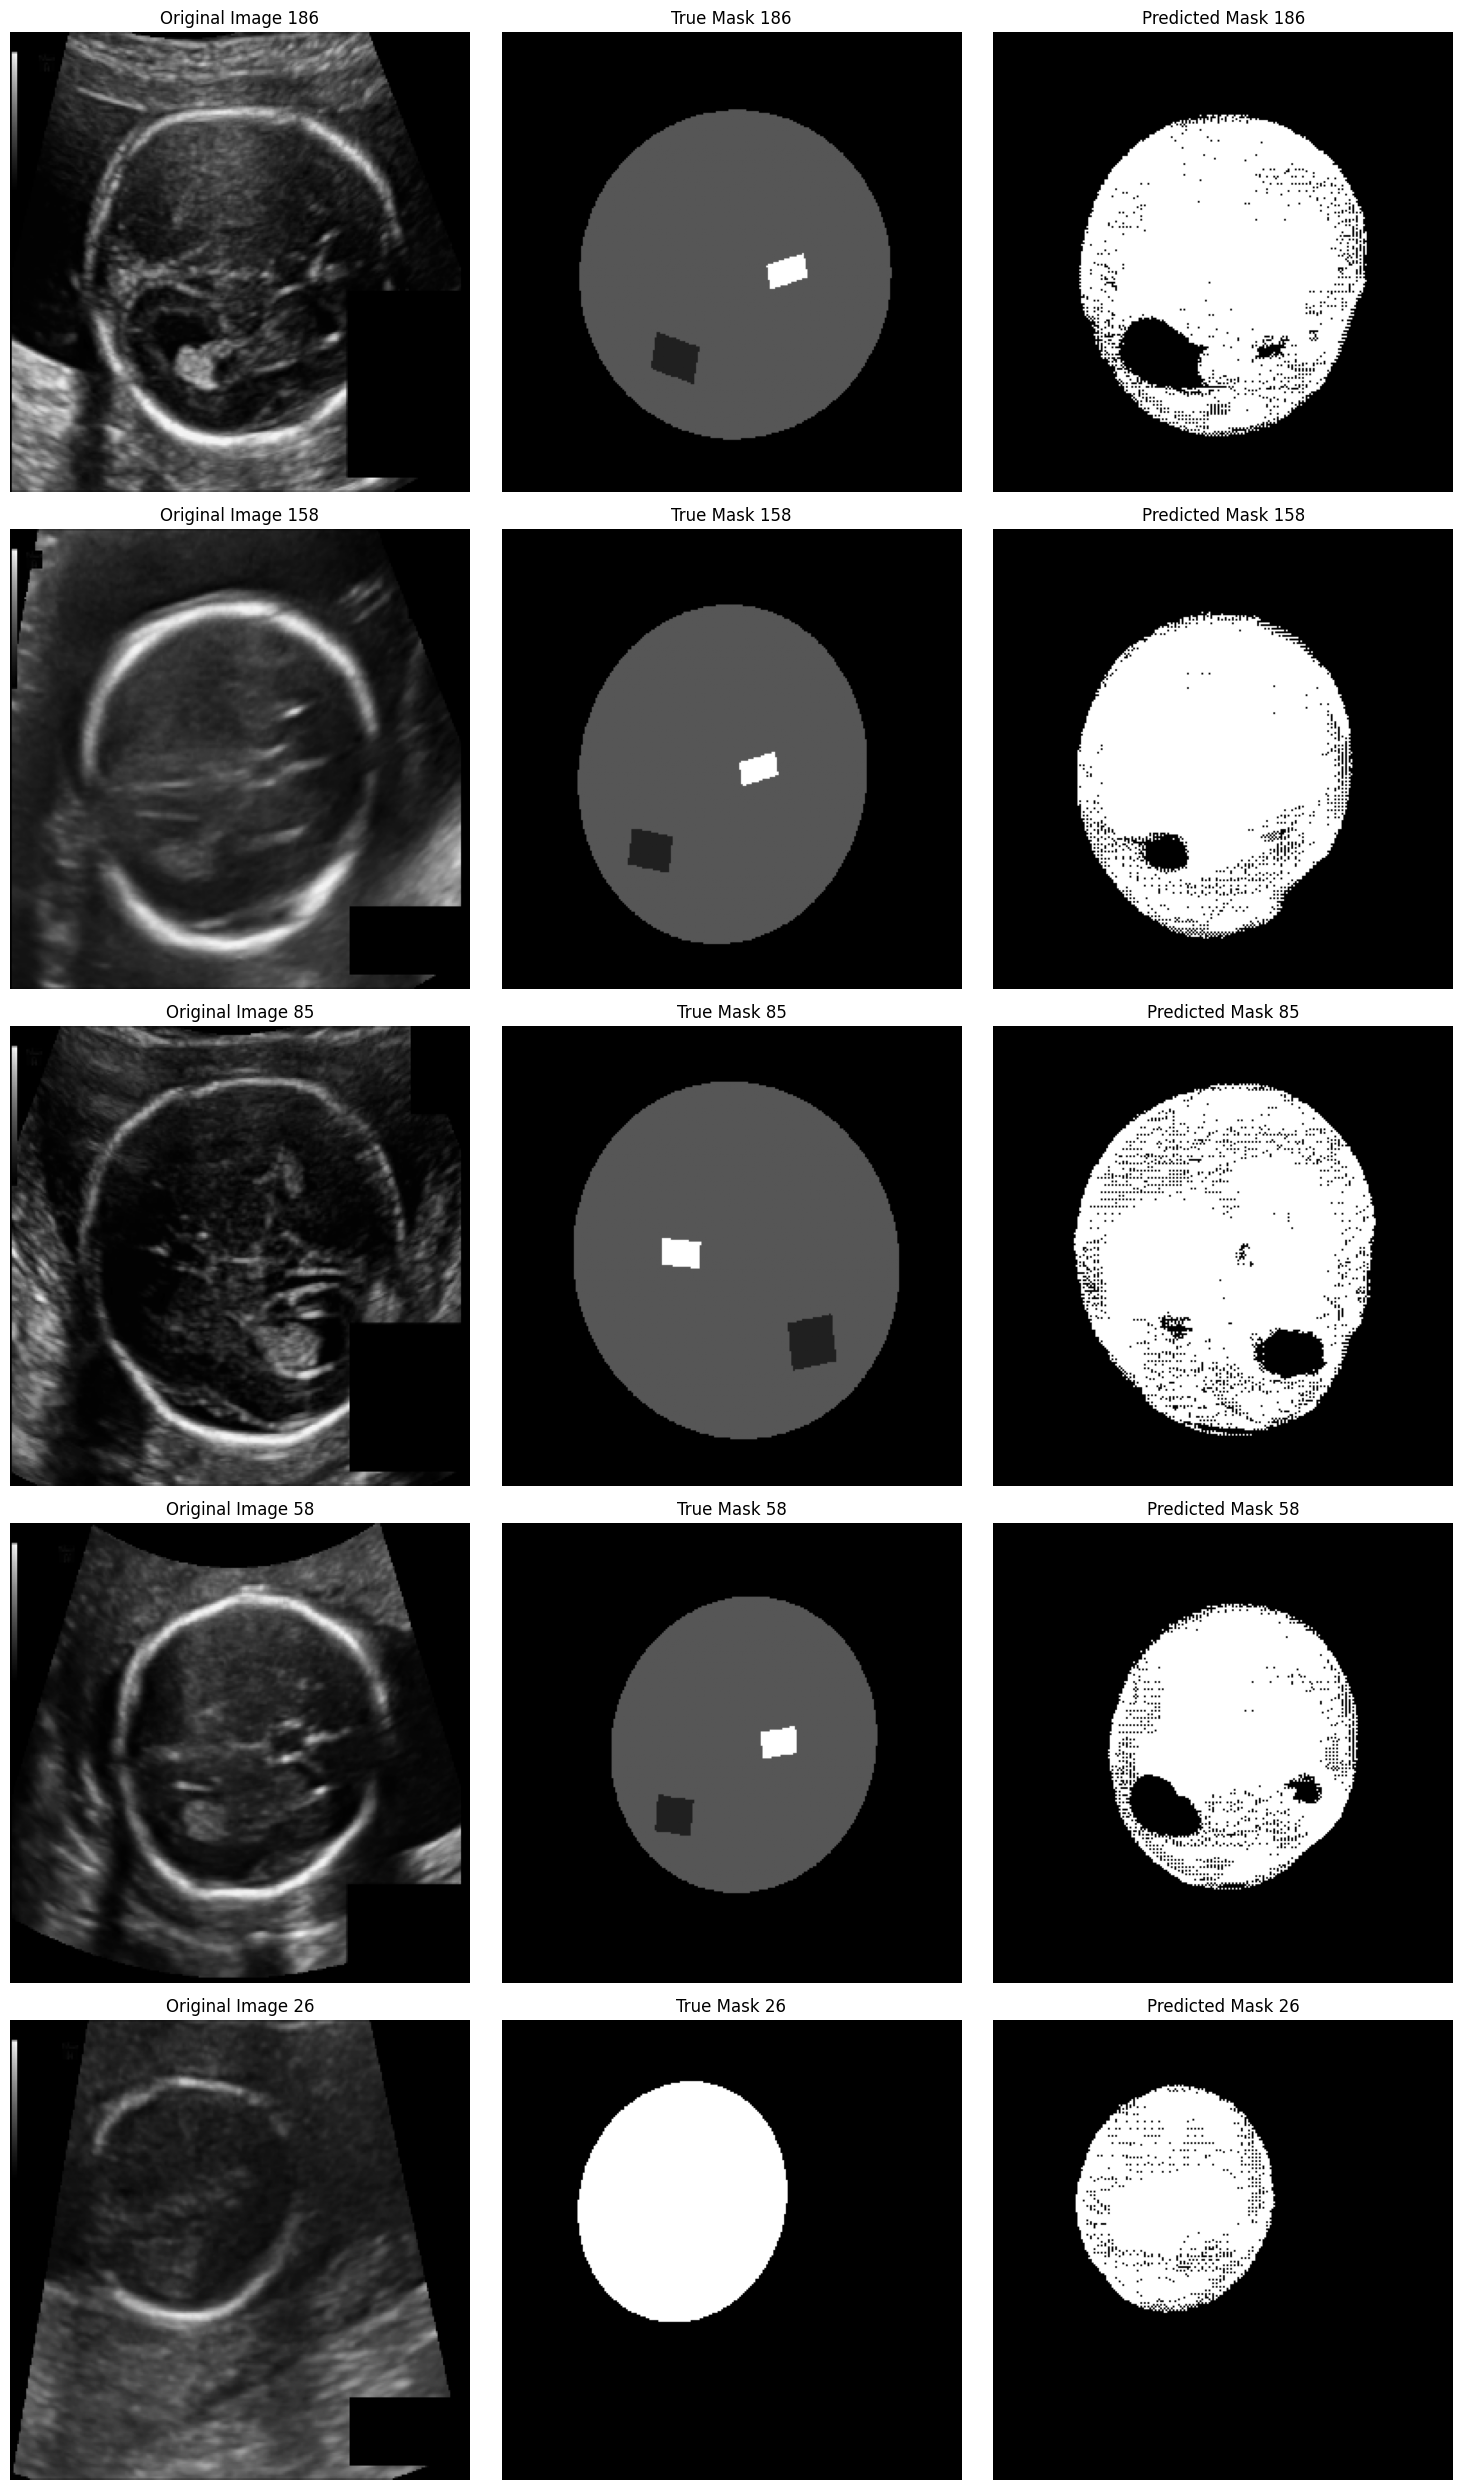

In [ ]:
import random

# Get a few random indices from the validation set
num_samples_to_visualize = 5
random_indices = random.sample(range(len(val_generator.image_filenames)), num_samples_to_visualize)

plt.figure(figsize=(15, num_samples_to_visualize * 5))

for i, idx in enumerate(random_indices):
    # Load original image and mask using the generator's internal methods
    image_path = val_generator.image_filenames[idx]
    mask_path = val_generator.mask_filenames[idx]

    original_image = val_generator._load_image(image_path)
    true_mask = val_generator._load_mask(mask_path)

    # The model expects a batch, so expand dimensions
    input_image = np.expand_dims(original_image, axis=0)

    # Make prediction
    # The model outputs two masks: final_output and output_unet1. We care about final_output.
    predictions = model.predict(input_image)
    predicted_mask_final = predictions[0][0] # Assuming final_output is the first prediction

    # For binary segmentation, apply a threshold to get binary mask
    predicted_mask_binary = (predicted_mask_final > 0.5).astype(np.float32)

    # Plot original image
    plt.subplot(num_samples_to_visualize, 3, i * 3 + 1)
    plt.imshow(original_image)
    plt.title(f'Original Image {idx}')
    plt.axis('off')

    # Plot true mask
    plt.subplot(num_samples_to_visualize, 3, i * 3 + 2)
    plt.imshow(true_mask[:, :, 0], cmap='gray') # Assuming single channel mask
    plt.title(f'True Mask {idx}')
    plt.axis('off')

    # Plot predicted mask
    plt.subplot(num_samples_to_visualize, 3, i * 3 + 3)
    plt.imshow(predicted_mask_binary[:, :, 0], cmap='gray') # Assuming single channel mask
    plt.title(f'Predicted Mask {idx}')
    plt.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
output_plot_filename = 'segmentation_predictions_comparison.pdf'
plt.savefig(output_plot_filename)
print(f"Visual comparisons saved to {output_plot_filename}")

Visual comparisons saved to segmentation_predictions_comparison.pdf


<Figure size 640x480 with 0 Axes>

In [ ]:
from tensorflow.keras.optimizers import AdamW
from tensorflow.keras.losses import BinaryCrossentropy
from tensorflow.keras.metrics import MeanIoU
from tensorflow.keras import backend as K
import tensorflow as tf # Import tensorflow to use tf.cast

# Custom Dice Loss function
def dice_loss(y_true, y_pred):
    y_true = tf.cast(y_true, tf.float32) # Ensure y_true is float32
    y_pred = tf.cast(y_pred, tf.float32) # Ensure y_pred is float32
    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(y_pred)
    intersection = K.sum(y_true_f * y_pred_f)
    return 1 - (2. * intersection + K.epsilon()) / (K.sum(y_true_f) + K.sum(y_pred_f) + K.epsilon())

# Combined Loss (Dice + Binary Crossentropy)
def combined_loss(y_true, y_pred):
    bce = BinaryCrossentropy()(y_true, y_pred)
    dice = dice_loss(y_true, y_pred)
    return bce + dice

# Compile the model
optimizer = AdamW(learning_rate=1e-4) # Changed to AdamW

# Define loss functions for each output
losses = {
    'final_output': combined_loss, # Using combined loss
    'output_unet1': combined_loss  # Using combined loss
}

# Assign loss weights for deep supervision, emphasizing the final output
loss_weights = {'final_output': 1.0, 'output_unet1': 0.5}

metrics = {
    'final_output': ['accuracy', MeanIoU(num_classes=2, name='iou')],
    'output_unet1': ['accuracy', MeanIoU(num_classes=2, name='iou')]
}

model.compile(optimizer=optimizer, loss=losses, loss_weights=loss_weights, metrics=metrics)

print("Model compiled successfully with AdamW, combined loss, and deep supervision!")

Model compiled successfully with AdamW, combined loss, and deep supervision!


In [ ]:
import pandas as pd

# List to store results
dice_scores = []

print("Calculating Dice coefficients for validation set...")

# Iterate through the validation generator
for i in range(len(val_generator)):
    X_batch, y_batch = val_generator[i]

    # Make prediction for the batch
    predictions = model.predict(X_batch, verbose=0) # Suppress verbose output for batch predictions
    predicted_masks_final = predictions[0] # Get the final_output predictions

    # Get true masks for the batch (final_output)
    true_masks_final = y_batch['final_output']

    for j in range(X_batch.shape[0]): # Iterate through samples in the batch
        # Get original image filename
        original_idx = val_generator.indexes[i * val_generator.batch_size + j]
        image_filename = os.path.basename(val_generator.image_filenames[original_idx])

        true_mask = true_masks_final[j]
        predicted_mask = (predicted_masks_final[j] > 0.5).astype(np.float32) # Binarize predicted mask

        # Reshape if necessary (e.g., remove singleton dimension if mask is (H, W, 1))
        true_mask_flat = K.flatten(true_mask)
        predicted_mask_flat = K.flatten(predicted_mask)

        # Calculate Dice coefficient using the previously defined function
        score = 1 - K.eval(dice_loss(true_mask_flat, predicted_mask_flat))

        dice_scores.append({
            'image_filename': image_filename,
            'dice_coefficient': score
        })

print("Dice coefficient calculation complete.")

# Convert to DataFrame and save to CSV
dice_df = pd.DataFrame(dice_scores)
csv_filename = 'validation_dice_coefficients.csv'
dice_df.to_csv(csv_filename, index=False)

print(f"Dice coefficients saved to {csv_filename}")
display(dice_df.head())

Calculating Dice coefficients for validation set...
Dice coefficient calculation complete.
Dice coefficients saved to validation_dice_coefficients.csv


,image_filename,dice_coefficient
0,Patient01779_Plane3_1_of_4.png,0.425125
1,Patient00695_Plane3_1_of_4.png,0.394673
2,Patient01057_Plane3_1_of_3.png,0.412680
3,Patient01051_Plane3_3_of_4.png,0.428978
4,Patient01109_Plane3_1_of_1.png,0.373669


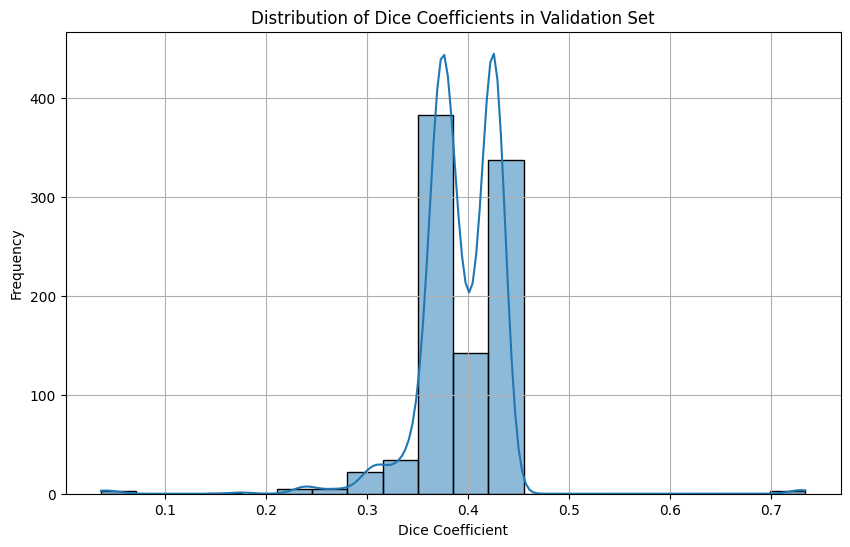

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Plotting the distribution of Dice coefficients
plt.figure(figsize=(10, 6))
sns.histplot(dice_df['dice_coefficient'], bins=20, kde=True)
plt.title('Distribution of Dice Coefficients in Validation Set')
plt.xlabel('Dice Coefficient')
plt.ylabel('Frequency')
plt.grid(True)
plt.show()

In [ ]:
from tensorflow.keras.losses import BinaryCrossentropy
import pandas as pd
import numpy as np

bce_scores = []
bce_fn = BinaryCrossentropy(reduction=tf.keras.losses.Reduction.NONE)

print("Calculating Binary Crossentropy for validation set...")

for i in range(len(val_generator)):
    X_batch, y_batch = val_generator[i]

    predictions = model.predict(X_batch, verbose=0)
    predicted_masks_final = predictions[0] # Get the final_output predictions

    true_masks_final = y_batch['final_output']

    for j in range(X_batch.shape[0]):
        original_idx = val_generator.indexes[i * val_generator.batch_size + j]
        image_filename = os.path.basename(val_generator.image_filenames[original_idx])

        true_mask = true_masks_final[j]
        predicted_mask = predicted_masks_final[j]


        bce_value = bce_fn(true_mask, predicted_mask)
        bce_value = tf.reduce_mean(bce_value).numpy() # Get the mean BCE for the image

        bce_scores.append({
            'image_filename': image_filename,
            'bce_loss': bce_value
        })

print("Binary Crossentropy calculation complete.")

bce_df = pd.DataFrame(bce_scores)
csv_filename_bce = 'validation_bce_losses.csv'
bce_df.to_csv(csv_filename_bce, index=False)

print(f"BCE losses saved to {csv_filename_bce}")
display(bce_df.head())


Calculating Binary Crossentropy for validation set...
Binary Crossentropy calculation complete.
BCE losses saved to validation_bce_losses.csv


,image_filename,bce_loss
0,Patient01779_Plane3_1_of_4.png,0.274525
1,Patient00695_Plane3_1_of_4.png,0.228029
2,Patient01057_Plane3_1_of_3.png,0.199520
3,Patient01051_Plane3_3_of_4.png,0.310836
4,Patient01109_Plane3_1_of_1.png,0.265950


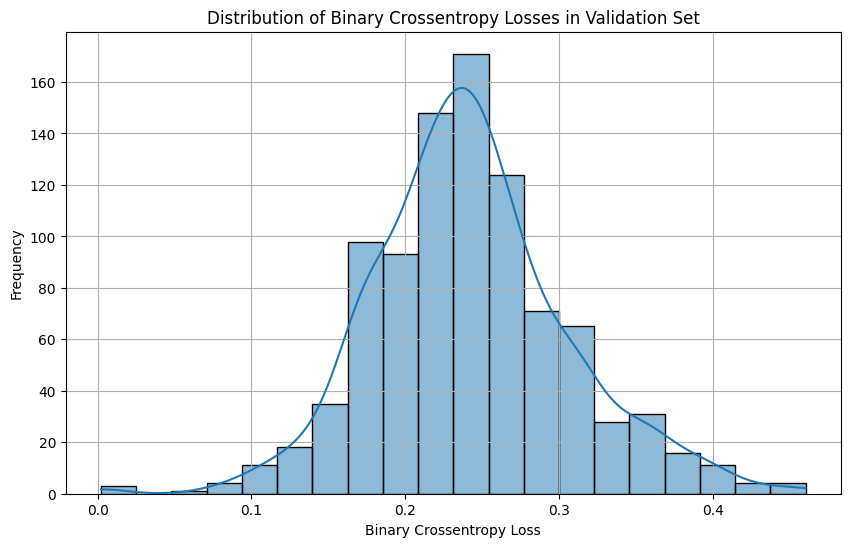

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Plotting the distribution of BCE losses
plt.figure(figsize=(10, 6))
sns.histplot(bce_df['bce_loss'], bins=20, kde=True)
plt.title('Distribution of Binary Crossentropy Losses in Validation Set')
plt.xlabel('Binary Crossentropy Loss')
plt.ylabel('Frequency')
plt.grid(True)
plt.show()

In [ ]:
import os
from tensorflow.keras.preprocessing.image import save_img

# Define the directory to save predicted masks
output_mask_dir = '/content/predicted_segmentation_masks'
os.makedirs(output_mask_dir, exist_ok=True)

print(f"Saving predicted masks to: {output_mask_dir}")

# Iterate through the validation generator to get images and make predictions
for i in range(len(val_generator)):
    X_batch, y_batch = val_generator[i]

    # Make prediction for the batch
    predictions = model.predict(X_batch, verbose=0)
    predicted_masks_final = predictions[0] # Get the final_output predictions

    # Iterate through each image in the batch
    for j in range(X_batch.shape[0]):
        # Get original image filename to use for naming the predicted mask
        original_idx = val_generator.indexes[i * val_generator.batch_size + j]
        image_filename = os.path.basename(val_generator.image_filenames[original_idx])

        # Get the predicted mask for the current image
        predicted_mask_raw = predicted_masks_final[j]

        # Binarize the predicted mask (threshold at 0.5)
        predicted_mask_binary = (predicted_mask_raw > 0.5).astype(np.float32)

        # Construct the output filename for the predicted mask
        # Replace original extension with .png and prepend 'predicted_'
        mask_output_filename = os.path.join(output_mask_dir, f"predicted_{os.path.splitext(image_filename)[0]}.png")

        # Save the predicted mask. Ensure it's in a format suitable for saving (e.g., 0-255 uint8)
        # Multiply by 255 if it's 0-1 float to make it visible
        save_img(mask_output_filename, predicted_mask_binary * 255.0)

print("All predicted masks saved successfully!")
print(f"You can find them in the directory: {output_mask_dir}")

Saving predicted masks to: /content/predicted_segmentation_masks
All predicted masks saved successfully!
You can find them in the directory: /content/predicted_segmentation_masks


Displaying 5 random predicted masks:


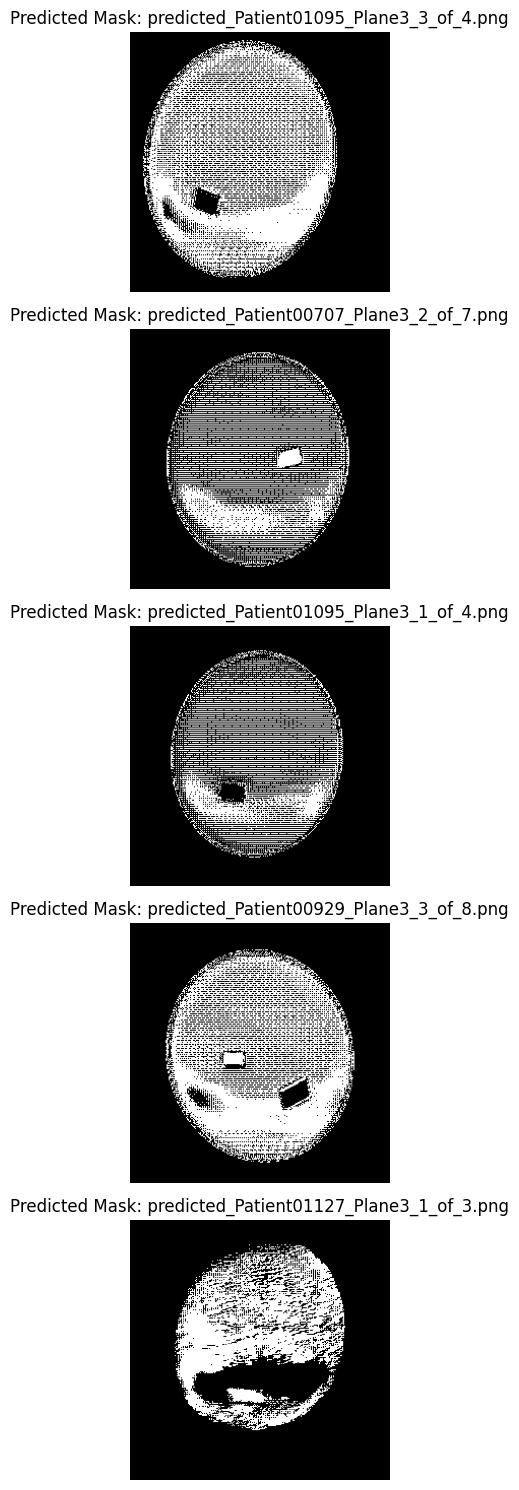

In [ ]:
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import load_img, img_to_array
import random
import os

output_mask_dir = '/content/predicted_segmentation_masks'

# Get a list of all predicted mask filenames
predicted_mask_files = [f for f in os.listdir(output_mask_dir) if f.startswith('predicted_') and f.endswith('.png')]

if not predicted_mask_files:
    print("No predicted masks found in the directory. Please ensure the previous step ran correctly.")
else:
    # Select a few random predicted masks to display
    num_masks_to_display = min(5, len(predicted_mask_files)) # Display up to 5 masks
    random_mask_filenames = random.sample(predicted_mask_files, num_masks_to_display)

    plt.figure(figsize=(15, num_masks_to_display * 3))

    print(f"Displaying {num_masks_to_display} random predicted masks:")
    for i, mask_filename in enumerate(random_mask_filenames):
        mask_path = os.path.join(output_mask_dir, mask_filename)
        predicted_mask = load_img(mask_path, color_mode='grayscale')
        predicted_mask = img_to_array(predicted_mask) / 255.0 # Normalize for display

        plt.subplot(num_masks_to_display, 1, i + 1)
        plt.imshow(predicted_mask[:, :, 0], cmap='gray')
        plt.title(f'Predicted Mask: {mask_filename}')
        plt.axis('off')

    plt.tight_layout()
    plt.show()

In [ ]:
import shutil
import os

output_mask_dir = '/content/predicted_segmentation_masks'
zip_output_path = '/content/predicted_segmentation_masks.zip'

print(f"Creating zip archive of predicted masks from {output_mask_dir}...")
shutil.make_archive(os.path.splitext(zip_output_path)[0], 'zip', output_mask_dir)

print(f"All predicted segmentation masks have been zipped to: {zip_output_path}")
print("You can now download this zip file from the Colab file browser.")

Creating zip archive of predicted masks from /content/predicted_segmentation_masks...
All predicted segmentation masks have been zipped to: /content/predicted_segmentation_masks.zip
You can now download this zip file from the Colab file browser.


In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from IPython.display import Image, display
import matplotlib.pyplot as plt
import matplotlib.cm as cm

def get_img_array(img_path, size):
    # `img` is a PIL image correctly resized
    img = keras.preprocessing.image.load_img(img_path, target_size=size)
    # `array` is a float32 NumPy array of shape (299, 299, 3)
    array = keras.preprocessing.image.img_to_array(img)
    # Normalize to [0, 1] to match model's expected input range
    array = array / 255.0
    # We add a dimension to transform our array into a batch of size (1, 299, 299, 3)
    array = np.expand_dims(array, axis=0)
    return array

In [ ]:
def save_and_display_gradcam(img_path, heatmap, alpha=0.4):
    # Load the original image
    img = keras.preprocessing.image.load_img(img_path)
    img = keras.preprocessing.image.img_to_array(img)
    img = img / 255.0 # Normalize image to [0, 1] for consistent blending

    # Rescale heatmap to a range 0-255 (temporarily for colormap application)
    heatmap_scaled_for_cmap = np.uint8(255 * heatmap)

    # Use jet colormap to colorize heatmap
    jet = cm.get_cmap("jet")

    # Use RGB values of the colormap
    jet_colors = jet(np.arange(256))[:, :3]
    jet_heatmap = jet_colors[heatmap_scaled_for_cmap] # This will be 0-1

    # Create an image with RGB colorized heatmap
    jet_heatmap = keras.preprocessing.image.array_to_img(jet_heatmap)
    jet_heatmap = jet_heatmap.resize((img.shape[1], img.shape[0]))
    jet_heatmap = keras.preprocessing.image.img_to_array(jet_heatmap) # Still 0-1 here

    # Superimpose the heatmap on original image
    # Both img and jet_heatmap are now 0-1, so blending should work correctly
    superimposed_img = jet_heatmap * alpha + img * (1 - alpha) # Blend original image with heatmap
    superimposed_img = np.clip(superimposed_img, 0, 1) # Clip values to ensure they stay within [0,1]

    # Convert back to 0-255 for saving
    superimposed_img = keras.preprocessing.image.array_to_img(superimposed_img * 255.0)

    # Save the superimposed image
    output_path = "gradcam_image.jpg"
    superimposed_img.save(output_path)

    display(Image(output_path))

In [ ]:
def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):
    # First, we create a model that maps the input image to the activations
    # of the last convolutional layer as well as the output predictions
    # `model.input` (singular) refers to the single Input tensor of the model.
    grad_model = tf.keras.models.Model(
        model.input, [model.get_layer(last_conv_layer_name).output, model.output]
    )

    # Then, we compute the gradient of the top predicted class for our input image
    # with respect to the activations of the last convolutional layer
    with tf.GradientTape() as tape:
        # Pass the image array directly to grad_model, as it expects a single tensor input.
        last_conv_layer_output, preds = grad_model(img_array)
        # For segmentation, we want the gradient with respect to the output mask directly.
        # The output 'preds' is a list [final_output, output_unet1]. We take final_output.
        # We need to sum over the spatial dimensions to get a single scalar for gradient calculation.
        # We'll take the mean of the final output mask as the 'score' for Grad-CAM.
        score = tf.reduce_mean(preds[0]) # Assuming preds[0] is 'final_output'

    # This is the gradient of the output neuron (top predicted or chosen) with regard to
    # the output feature map of the last convolutional layer
    grads = tape.gradient(score, last_conv_layer_output)

    # We pool the gradients over all the axes leaving the channel dimension
    # or reshape to fit a more standard global average pooling approach
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    # We multiply each channel in the feature map array by "how important" this channel is
    # with regard to the selected output
    last_conv_layer_output = last_conv_layer_output[0]
    heatmap = last_conv_layer_output @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    # For visualization, we normalize the heatmap between 0 and 1
    max_heatmap = tf.reduce_max(heatmap)
    if max_heatmap == 0:
        # If max is 0, the heatmap is all zeros, return an array of zeros
        return np.zeros_like(heatmap.numpy())
    heatmap = tf.maximum(heatmap, 0) / (max_heatmap + tf.keras.backend.epsilon()) # Add epsilon to avoid division by zero
    return heatmap.numpy()

/usr/local/lib/python3.12/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor']
Received: inputs=Tensor(shape=(1, 256, 256, 3))
  warnings.warn(msg)


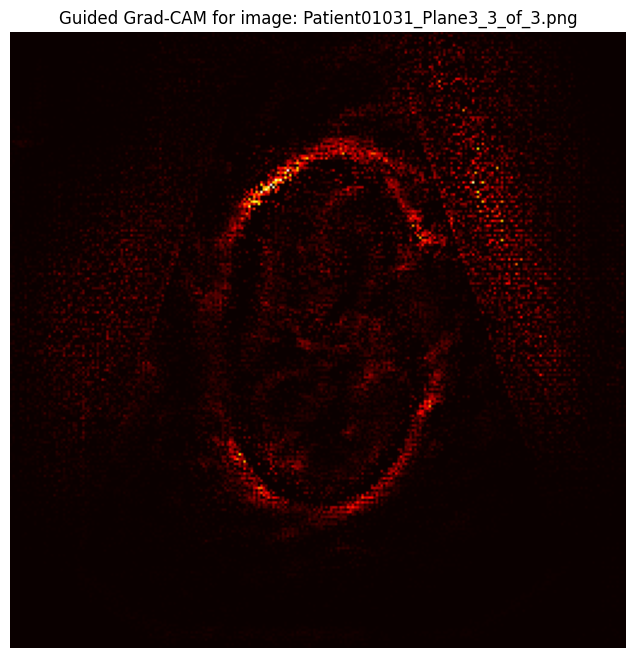

Guided Grad-CAM for image: Patient01031_Plane3_3_of_3.png


In [ ]:
# This part of the implementation requires modifying the TensorFlow graph to perform Guided Backpropagation.
# For TF2, the Guided Backprop part often involves creating a custom gradient function or using existing implementations.
# A common approach is to use the `tf.compat.v1.disable_eager_execution()` and register the custom gradient.
# However, it's more straightforward in TF2 to directly compute gradients where negative gradients are set to zero.

@tf.custom_gradient
def guided_relu(x):
    def grad(dy):
        return tf.cast(dy > 0, dy.dtype) * tf.cast(x > 0, x.dtype) * dy
    return tf.nn.relu(x), grad

# The `build_guided_model` function in the original prompt is overly complex for directly modifying
# activations in a functional model and is not strictly necessary for computing Guided Backprop gradients.
# We will instead rely on direct gradient computation as per the commented section in the original code,
# and ensure proper handling of potential division by zero for normalization.

# --- Variable setup for Grad-CAM and Guided Grad-CAM ---
# Get a random image from the validation set
# Assuming val_generator is accessible from previous cells.
idx = np.random.randint(0, len(val_generator.image_filenames))
img_path_for_gradcam = val_generator.image_filenames[idx]

# Get an image array for the selected image
img_size = (256, 256) # Must match model's input size
# Assuming get_img_array is defined in a previous cell (e.g., ee973b83)
img_array_for_gradcam = get_img_array(img_path_for_gradcam, size=img_size)

# The name of the last convolutional layer. This should be 'conv2d_17' for the current model.
last_conv_layer_name = "conv2d_17"

# Generate heatmap (assuming make_gradcam_heatmap is defined in a previous cell, e.g., 7e799d27)
heatmap = make_gradcam_heatmap(img_array_for_gradcam, model, last_conv_layer_name)
# --- End Variable setup ---


# Calculate Guided Backprop gradients
with tf.GradientTape() as tape:
    # Ensure img_array_for_gradcam is a tf.Tensor to be watched by GradientTape
    img_tensor_for_gradcam = tf.constant(img_array_for_gradcam, dtype=tf.float32)
    tape.watch(img_tensor_for_gradcam)
    # Get the score from the model's final output (e.g., mean of the predicted mask)
    preds = model([img_tensor_for_gradcam]) # Wrap input in a list
    score = tf.reduce_mean(preds[0]) # Assuming preds[0] is 'final_output'

# Compute gradients of the score with respect to the input image
guided_grads = tape.gradient(score, img_tensor_for_gradcam) # Gradients for the entire input tensor
guided_grads = guided_grads[0] # Take the gradients for the single image in the batch

# Now, combine with the Grad-CAM heatmap
# Element-wise multiplication of the guided gradients and the upsampled heatmap
# The heatmap needs to be upsampled to the original image size
upsampled_heatmap = tf.image.resize(tf.expand_dims(heatmap, axis=-1), img_size)

# Apply ReLU to guided_grads (they can be negative) to match the original Guided Backprop concept
guided_grads = tf.cast(guided_grads, tf.float32)
guided_grads = tf.maximum(guided_grads, 0)

guided_grad_cam = guided_grads * upsampled_heatmap

# Normalize for display, handling potential division by zero
guided_grad_cam_display = guided_grad_cam.numpy()
min_val = guided_grad_cam_display.min()
max_val = guided_grad_cam_display.max()

if (max_val - min_val) == 0:
    # If min and max are the same, the array is flat (all same value), return zeros or a constant
    guided_grad_cam_display = np.zeros_like(guided_grad_cam_display)
else:
    guided_grad_cam_display = (guided_grad_cam_display - min_val) / (max_val - min_val)

# Save and display Guided Grad-CAM
plt.figure(figsize=(8, 8))
plt.imshow(guided_grad_cam_display[..., 0], cmap='hot') # Display one channel for grayscale effect
plt.title(f'Guided Grad-CAM for image: {os.path.basename(img_path_for_gradcam)}')
plt.axis('off')
plt.savefig("guided_gradcam_image.jpg")
plt.show()

print(f"Guided Grad-CAM for image: {os.path.basename(img_path_for_gradcam)}")

/usr/local/lib/python3.12/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor']
Received: inputs=Tensor(shape=(1, 256, 256, 3))
  warnings.warn(msg)


Grad-CAM for image: Patient01596_Plane3_2_of_5.png


/tmp/ipykernel_481/432121539.py:11: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  jet = cm.get_cmap("jet")


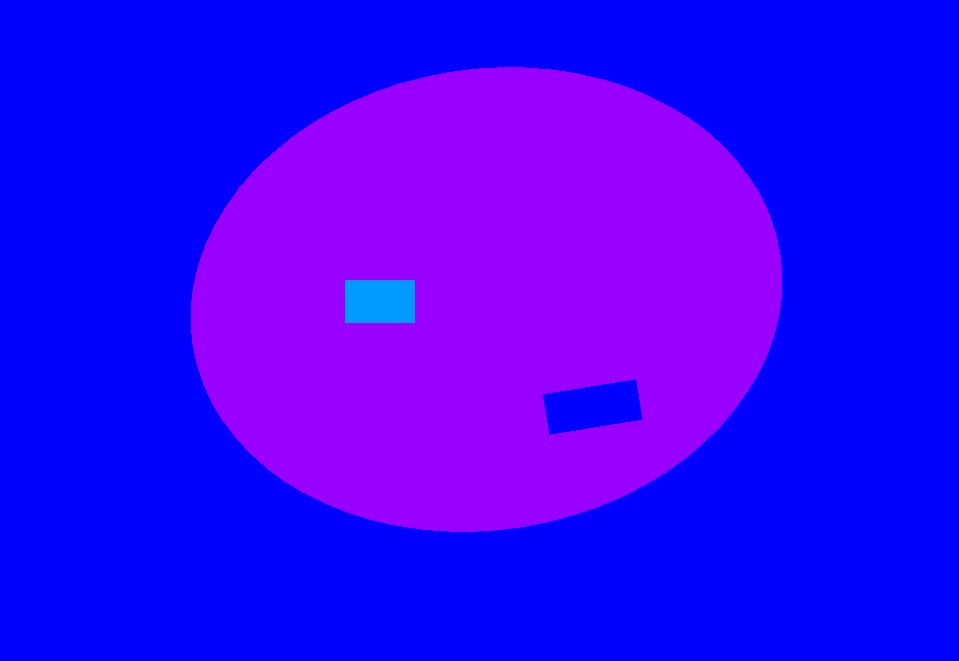

In [ ]:
# Re-executing Grad-CAM to display corrected heatmap
# Select a random image from the validation set
idx = np.random.randint(0, len(val_generator.image_filenames))
img_path_for_gradcam = val_generator.image_filenames[idx]

# Get an image array for the selected image
img_size = (256, 256) # Must match model's input size
img_array_for_gradcam = get_img_array(img_path_for_gradcam, size=img_size)

# The name of the last convolutional layer. You might need to inspect model.summary() for this.
# Based on the model definition, a good candidate would be 'conv2d_17' (the last conv_block's second Conv2D in the final decoder block)
# or 'conv2d_16' (the first Conv2D of the last conv_block in the final decoder block).
# Let's try 'conv2d_17' from the final_output path.
last_conv_layer_name = "conv2d_17" # This needs to be the actual name of your last conv layer before the output activation

# Generate heatmap
heatmap = make_gradcam_heatmap(img_array_for_gradcam, model, last_conv_layer_name)

# Display Grad-CAM
print(f"Grad-CAM for image: {os.path.basename(img_path_for_gradcam)}")
save_and_display_gradcam(img_path_for_gradcam, heatmap)

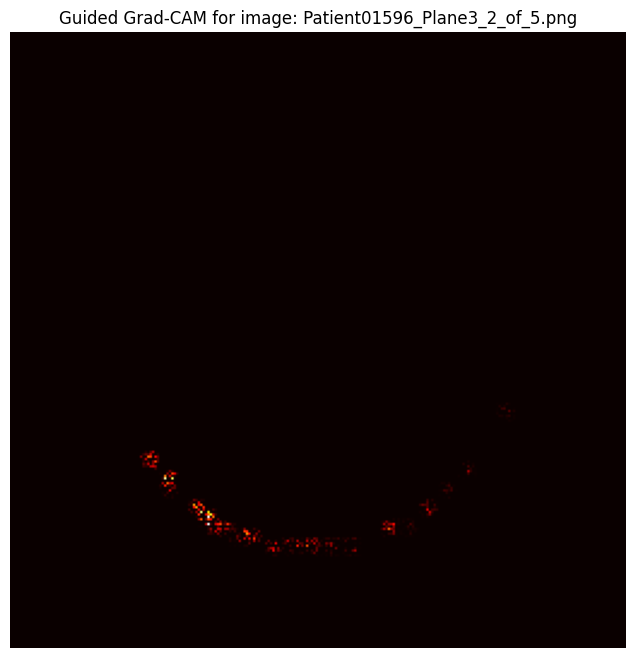

Guided Grad-CAM for image: Patient01596_Plane3_2_of_5.png


In [ ]:
# Re-executing Guided Grad-CAM to display corrected heatmap

# Calculate Guided Backprop gradients
with tf.GradientTape() as tape:
    # Ensure img_array_for_gradcam is a tf.Tensor to be watched by GradientTape
    img_tensor_for_gradcam = tf.constant(img_array_for_gradcam, dtype=tf.float32)
    tape.watch(img_tensor_for_gradcam)
    # Get the score from the model's final output (e.g., mean of the predicted mask)
    # Pass the image tensor directly to the model, not wrapped in an extra list
    preds = model(img_tensor_for_gradcam)
    score = tf.reduce_mean(preds[0]) # Assuming preds[0] is 'final_output'

# Compute gradients of the score with respect to the input image
# Note: We need to take the gradient with respect to the original input tensor, not the numpy array.
guided_grads = tape.gradient(score, img_tensor_for_gradcam) # Gradients for a single image
guided_grads = guided_grads[0] # Take the gradients for the single image in the batch

# Now, combine with the Grad-CAM heatmap
# Element-wise multiplication of the guided gradients and the upsampled heatmap
# The heatmap needs to be upsampled to the original image size
upsampled_heatmap = tf.image.resize(tf.expand_dims(heatmap, axis=-1), img_size)

# Apply ReLU to guided_grads (they can be negative) to match the original Guided Backprop concept
guided_grads = tf.cast(guided_grads, tf.float32)
guided_grads = tf.maximum(guided_grads, 0)

guided_grad_cam = guided_grads * upsampled_heatmap

# Normalize for display, handling potential division by zero
guided_grad_cam_display = guided_grad_cam.numpy()
min_val = guided_grad_cam_display.min()
max_val = guided_grad_cam_display.max()

if (max_val - min_val) == 0:
    # If min and max are the same, the array is flat (all same value), return zeros or a constant
    guided_grad_cam_display = np.zeros_like(guided_grad_cam_display)
else:
    guided_grad_cam_display = (guided_grad_cam_display - min_val) / (max_val - min_val)

# Save and display Guided Grad-CAM
plt.figure(figsize=(8, 8))
plt.imshow(guided_grad_cam_display[..., 0], cmap='hot') # Display one channel for grayscale effect
plt.title(f'Guided Grad-CAM for image: {os.path.basename(img_path_for_gradcam)}')
plt.axis('off')
plt.savefig("guided_gradcam_image.jpg")
plt.show()

print(f"Guided Grad-CAM for image: {os.path.basename(img_path_for_gradcam)}")

/usr/local/lib/python3.12/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor']
Received: inputs=Tensor(shape=(1, 256, 256, 3))
  warnings.warn(msg)


Grad-CAM for image: Patient01044_Plane3_4_of_5.png


/tmp/ipykernel_481/432121539.py:11: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  jet = cm.get_cmap("jet")


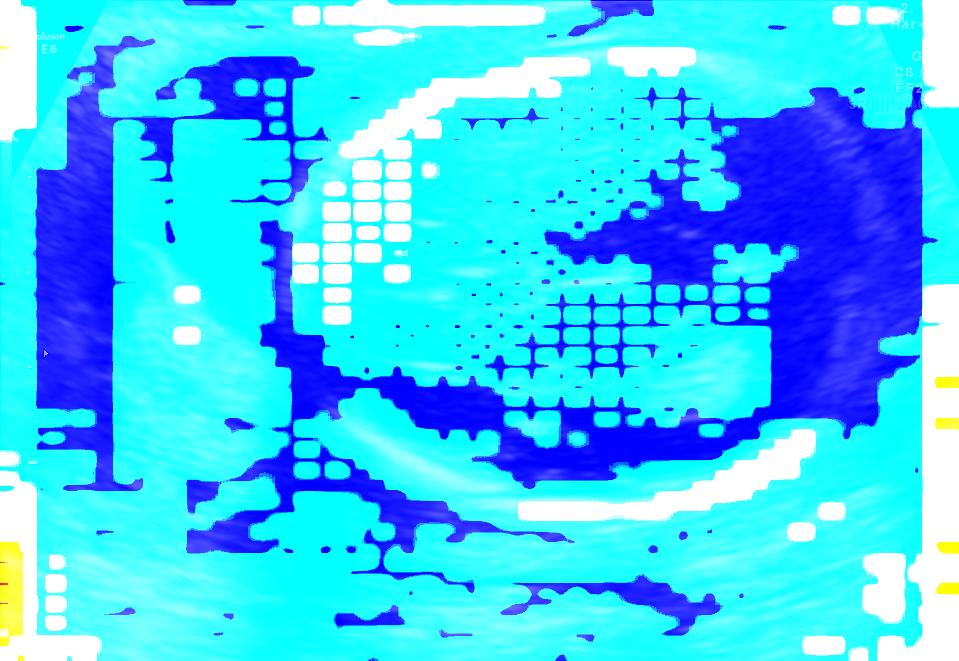

In [ ]:
# Re-executing Grad-CAM to display corrected heatmap
# Select a random image from the validation set
idx = np.random.randint(0, len(val_generator.image_filenames))
img_path_for_gradcam = val_generator.image_filenames[idx]

# Get an image array for the selected image
img_size = (256, 256) # Must match model's input size
img_array_for_gradcam = get_img_array(img_path_for_gradcam, size=img_size)

# The name of the last convolutional layer. You might need to inspect model.summary() for this.
# Based on the model definition, a good candidate would be 'conv2d_17' (the last conv_block's second Conv2D in the final decoder block)
# or 'conv2d_16' (the first Conv2D of the last conv_block in the final decoder block).
# Let's try 'conv2d_17' from the final_output path.
last_conv_layer_name = "conv2d_17" # This needs to be the actual name of your last conv layer before the output activation

# Generate heatmap
heatmap = make_gradcam_heatmap(img_array_for_gradcam, model, last_conv_layer_name)

# Display Grad-CAM
print(f"Grad-CAM for image: {os.path.basename(img_path_for_gradcam)}")
save_and_display_gradcam(img_path_for_gradcam, heatmap)

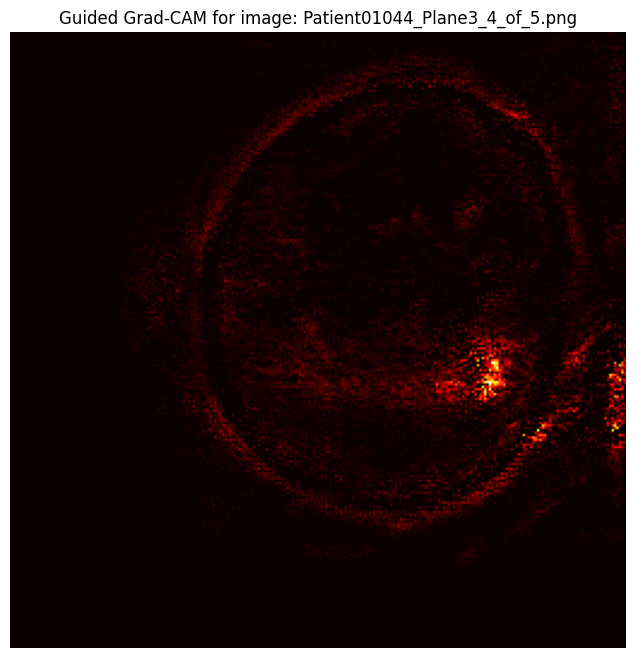

Guided Grad-CAM for image: Patient01044_Plane3_4_of_5.png


In [ ]:
# Re-executing Guided Grad-CAM to display corrected heatmap

# Calculate Guided Backprop gradients
with tf.GradientTape() as tape:
    # Ensure img_array_for_gradcam is a tf.Tensor to be watched by GradientTape
    img_tensor_for_gradcam = tf.constant(img_array_for_gradcam, dtype=tf.float32)
    tape.watch(img_tensor_for_gradcam)
    # Get the score from the model's final output (e.g., mean of the predicted mask)
    # Pass the image tensor directly to the model, not wrapped in an extra list
    preds = model(img_tensor_for_gradcam)
    score = tf.reduce_mean(preds[0]) # Assuming preds[0] is 'final_output'

# Compute gradients of the score with respect to the input image
# Note: We need to take the gradient with respect to the original input tensor, not the numpy array.
guided_grads = tape.gradient(score, img_tensor_for_gradcam) # Get gradients for the entire input tensor
guided_grads = guided_grads[0] # Take the gradients for the single image in the batch

# Now, combine with the Grad-CAM heatmap
# Element-wise multiplication of the guided gradients and the upsampled heatmap
# The heatmap needs to be upsampled to the original image size
upsampled_heatmap = tf.image.resize(tf.expand_dims(heatmap, axis=-1), img_size)

# Apply ReLU to guided_grads (they can be negative) to match the original Guided Backprop concept
guided_grads = tf.cast(guided_grads, tf.float32)
guided_grads = tf.maximum(guided_grads, 0)

guided_grad_cam = guided_grads * upsampled_heatmap

# Normalize for display, handling potential division by zero
guided_grad_cam_display = guided_grad_cam.numpy()
min_val = guided_grad_cam_display.min()
max_val = guided_grad_cam_display.max()

if (max_val - min_val) == 0:
    # If min and max are the same, the array is flat (all same value), return zeros or a constant
    guided_grad_cam_display = np.zeros_like(guided_grad_cam_display)
else:
    guided_grad_cam_display = (guided_grad_cam_display - min_val) / (max_val - min_val)

# Save and display Guided Grad-CAM
plt.figure(figsize=(8, 8))
plt.imshow(guided_grad_cam_display[..., 0], cmap='hot') # Display one channel for grayscale effect
plt.title(f'Guided Grad-CAM for image: {os.path.basename(img_path_for_gradcam)}')
plt.axis('off')
plt.savefig("guided_gradcam_image.jpg")
plt.show()

print(f"Guided Grad-CAM for image: {os.path.basename(img_path_for_gradcam)}")

/usr/local/lib/python3.12/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor']
Received: inputs=Tensor(shape=(1, 256, 256, 3))
  warnings.warn(msg)


Grad-CAM for image: Patient01052_Plane3_8_of_9.png


/tmp/ipykernel_481/432121539.py:11: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  jet = cm.get_cmap("jet")


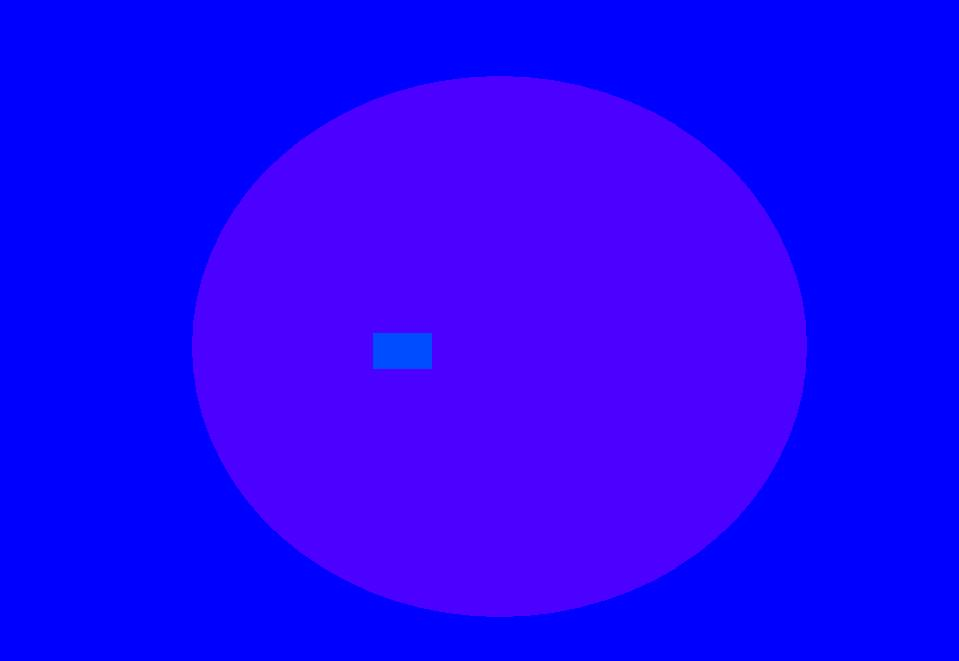

In [ ]:
# Re-executing Grad-CAM to display corrected heatmap
# Select a random image from the validation set
idx = np.random.randint(0, len(val_generator.image_filenames))
img_path_for_gradcam = val_generator.image_filenames[idx]

# Get an image array for the selected image
img_size = (256, 256) # Must match model's input size
img_array_for_gradcam = get_img_array(img_path_for_gradcam, size=img_size)

# The name of the last convolutional layer. You might need to inspect model.summary() for this.
# Based on the model definition, a good candidate would be 'conv2d_17' (the last conv_block's second Conv2D in the final decoder block)
# or 'conv2d_16' (the first Conv2D of the last conv_block in the final decoder block).
# Let's try 'conv2d_17' from the final_output path.
last_conv_layer_name = "conv2d_17" # This needs to be the actual name of your last conv layer before the output activation

# Generate heatmap
heatmap = make_gradcam_heatmap(img_array_for_gradcam, model, last_conv_layer_name)

# Display Grad-CAM
print(f"Grad-CAM for image: {os.path.basename(img_path_for_gradcam)}")
save_and_display_gradcam(img_path_for_gradcam, heatmap)

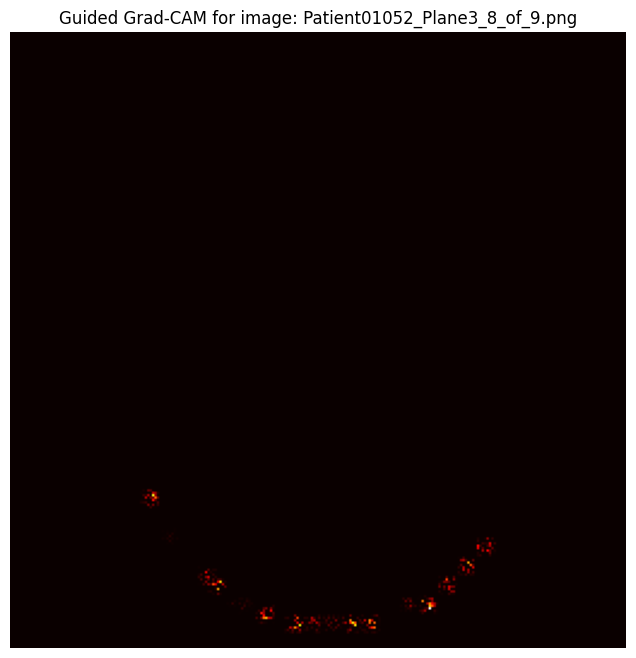

Guided Grad-CAM for image: Patient01052_Plane3_8_of_9.png


In [ ]:
# Re-executing Guided Grad-CAM to display corrected heatmap

# Calculate Guided Backprop gradients
with tf.GradientTape() as tape:
    # Ensure img_array_for_gradcam is a tf.Tensor to be watched by GradientTape
    img_tensor_for_gradcam = tf.constant(img_array_for_gradcam, dtype=tf.float32)
    tape.watch(img_tensor_for_gradcam)
    # Get the score from the model's final output (e.g., mean of the predicted mask)
    # Pass the image tensor directly to the model, as it expects a single tensor input.
    preds = model(img_tensor_for_gradcam)
    score = tf.reduce_mean(preds[0]) # Assuming preds[0] is 'final_output'

# Compute gradients of the score with respect to the input image
# Note: We need to take the gradient with respect to the original input tensor, not the numpy array.
guided_grads = tape.gradient(score, img_tensor_for_gradcam) # Get gradients for the entire input tensor
guided_grads = guided_grads[0] # Take the gradients for the single image in the batch

# Now, combine with the Grad-CAM heatmap
# Element-wise multiplication of the guided gradients and the upsampled heatmap
# The heatmap needs to be upsampled to the original image size
upsampled_heatmap = tf.image.resize(tf.expand_dims(heatmap, axis=-1), img_size)

# Apply ReLU to guided_grads (they can be negative) to match the original Guided Backprop concept
guided_grads = tf.cast(guided_grads, tf.float32)
guided_grads = tf.maximum(guided_grads, 0)

guided_grad_cam = guided_grads * upsampled_heatmap

# Normalize for display, handling potential division by zero
guided_grad_cam_display = guided_grad_cam.numpy()
min_val = guided_grad_cam_display.min()
max_val = guided_grad_cam_display.max()

if (max_val - min_val) == 0:
    # If min and max are the same, the array is flat (all same value), return zeros or a constant
    guided_grad_cam_display = np.zeros_like(guided_grad_cam_display)
else:
    guided_grad_cam_display = (guided_grad_cam_display - min_val) / (max_val - min_val)

# Save and display Guided Grad-CAM
plt.figure(figsize=(8, 8))
plt.imshow(guided_grad_cam_display[..., 0], cmap='hot') # Display one channel for grayscale effect
plt.title(f'Guided Grad-CAM for image: {os.path.basename(img_path_for_gradcam)}')
plt.axis('off')
plt.savefig("guided_gradcam_image.jpg")
plt.show()

print(f"Guided Grad-CAM for image: {os.path.basename(img_path_for_gradcam)}")

/usr/local/lib/python3.12/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor']
Received: inputs=Tensor(shape=(1, 256, 256, 3))
  warnings.warn(msg)


Grad-CAM for image: Patient01162_Plane3_1_of_3.png


/tmp/ipykernel_481/387870011.py:28: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  jet = cm.get_cmap("jet")


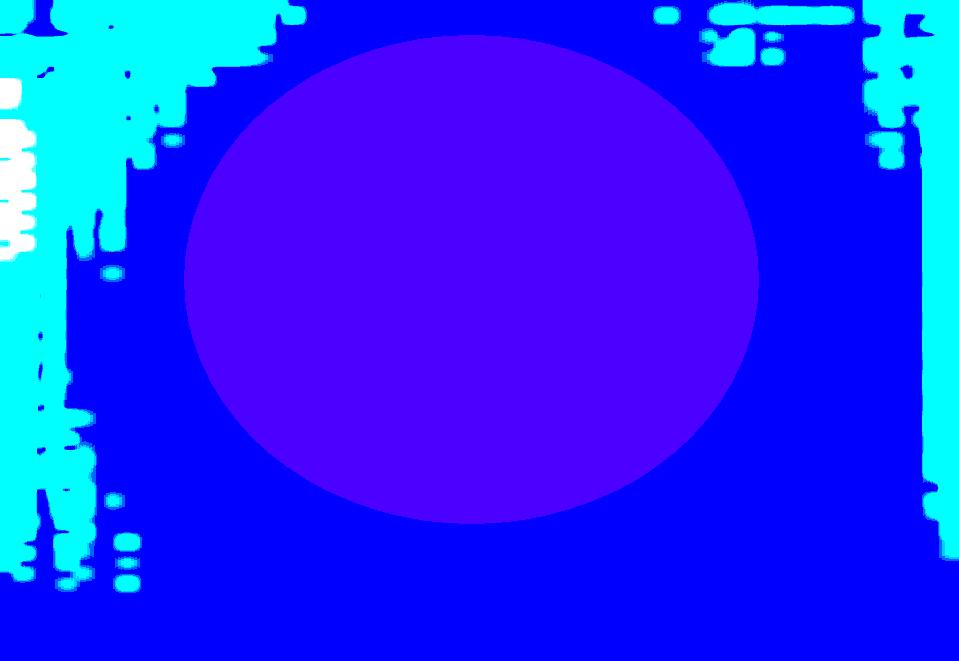

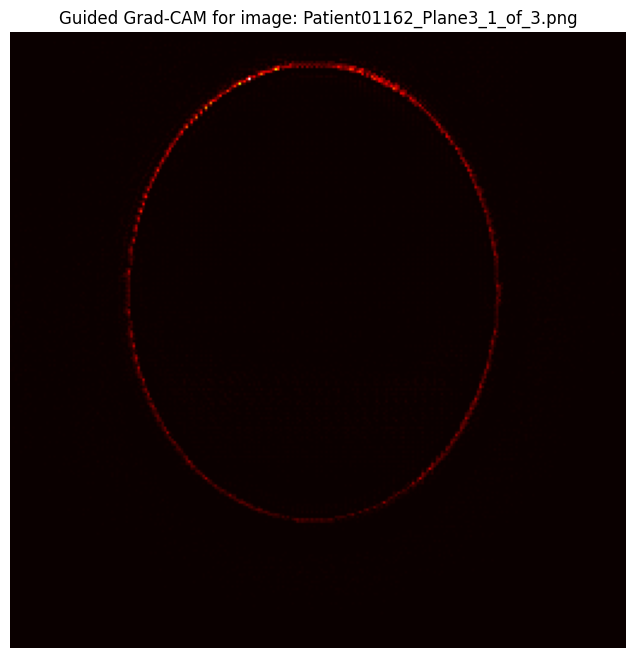

Guided Grad-CAM for image: Patient01162_Plane3_1_of_3.png


In [ ]:
# This cell combines all Grad-CAM and Guided Grad-CAM logic,
# including function definitions and their execution, to ensure all changes are applied.
# It will generate and display both Grad-CAM and Guided Grad-CAM for a random image.

# Define necessary imports (re-including them to ensure availability in this self-contained block)
import numpy as np
import tensorflow as tf
from tensorflow import keras
from IPython.display import Image, display
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import os

# Re-execute the definition of get_img_array (from cell ee973b83)
def get_img_array(img_path, size):
    img = keras.preprocessing.image.load_img(img_path, target_size=size)
    array = keras.preprocessing.image.img_to_array(img)
    array = array / 255.0
    array = np.expand_dims(array, axis=0)
    return array

# Re-execute the definition of save_and_display_gradcam (from cell 7cb4008e)
def save_and_display_gradcam(img_path, heatmap, alpha=0.4):
    img = keras.preprocessing.image.load_img(img_path)
    img = keras.preprocessing.image.img_to_array(img)
    img = img / 255.0
    heatmap_scaled_for_cmap = np.uint8(255 * heatmap)
    jet = cm.get_cmap("jet")
    jet_colors = jet(np.arange(256))[:, :3]
    jet_heatmap = jet_colors[heatmap_scaled_for_cmap]
    jet_heatmap = keras.preprocessing.image.array_to_img(jet_heatmap)
    jet_heatmap = jet_heatmap.resize((img.shape[1], img.shape[0]))
    jet_heatmap = keras.preprocessing.image.img_to_array(jet_heatmap)
    superimposed_img = jet_heatmap * alpha + img * (1 - alpha)
    superimposed_img = np.clip(superimposed_img, 0, 1)
    superimposed_img = keras.preprocessing.image.array_to_img(superimposed_img * 255.0)
    output_path = "gradcam_image.jpg"
    superimposed_img.save(output_path)
    display(Image(output_path))

# Re-execute the definition of make_gradcam_heatmap (from cell 7e799d27)
def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):
    grad_model = tf.keras.models.Model(
        model.input, [model.get_layer(last_conv_layer_name).output, model.output]
    )
    with tf.GradientTape() as tape:
        last_conv_layer_output, preds = grad_model(img_array)
        score = tf.reduce_mean(preds[0])
    grads = tape.gradient(score, last_conv_layer_output)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    last_conv_layer_output = last_conv_layer_output[0]
    heatmap = last_conv_layer_output @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    max_heatmap = tf.reduce_max(heatmap)
    if max_heatmap == 0:
        return np.zeros_like(heatmap.numpy())
    heatmap = tf.maximum(heatmap, 0) / (max_heatmap + tf.keras.backend.epsilon())
    return heatmap.numpy()

# --- Grad-CAM Execution ---

# Get a random image from the validation set
idx = np.random.randint(0, len(val_generator.image_filenames))
img_path_for_gradcam = val_generator.image_filenames[idx]

# Get an image array for the selected image
img_size = (256, 256) # Must match model's input size
img_array_for_gradcam = get_img_array(img_path_for_gradcam, size=img_size)

# The name of the last convolutional layer. This should be 'conv2d_17' for the current model.
last_conv_layer_name = "conv2d_17"

# Generate Grad-CAM heatmap
heatmap = make_gradcam_heatmap(img_array_for_gradcam, model, last_conv_layer_name)

# Display Grad-CAM
print(f"Grad-CAM for image: {os.path.basename(img_path_for_gradcam)}")
save_and_display_gradcam(img_path_for_gradcam, heatmap)

# --- Guided Grad-CAM Execution ---

# Calculate Guided Backprop gradients
with tf.GradientTape() as tape:
    img_tensor_for_gradcam = tf.constant(img_array_for_gradcam, dtype=tf.float32)
    tape.watch(img_tensor_for_gradcam)
    preds = model(img_tensor_for_gradcam)
    score = tf.reduce_mean(preds[0])

guided_grads = tape.gradient(score, img_tensor_for_gradcam)
guided_grads = guided_grads[0]

upsampled_heatmap = tf.image.resize(tf.expand_dims(heatmap, axis=-1), img_size)

guided_grads = tf.cast(guided_grads, tf.float32)
guided_grads = tf.maximum(guided_grads, 0)

guided_grad_cam = guided_grads * upsampled_heatmap

guided_grad_cam_display = guided_grad_cam.numpy()
min_val = guided_grad_cam_display.min()
max_val = guided_grad_cam_display.max()

if (max_val - min_val) == 0:
    guided_grad_cam_display = np.zeros_like(guided_grad_cam_display)
else:
    guided_grad_cam_display = (guided_grad_cam_display - min_val) / (max_val - min_val)

plt.figure(figsize=(8, 8))
plt.imshow(guided_grad_cam_display[..., 0], cmap='hot')
plt.title(f'Guided Grad-CAM for image: {os.path.basename(img_path_for_gradcam)}')
plt.axis('off')
plt.savefig("guided_gradcam_image.jpg")
plt.show()

print(f"Guided Grad-CAM for image: {os.path.basename(img_path_for_gradcam)}")

/usr/local/lib/python3.12/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor']
Received: inputs=Tensor(shape=(1, 256, 256, 3))
  warnings.warn(msg)


Grad-CAM for image: Patient00929_Plane3_1_of_8.png


/tmp/ipykernel_481/387870011.py:28: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  jet = cm.get_cmap("jet")


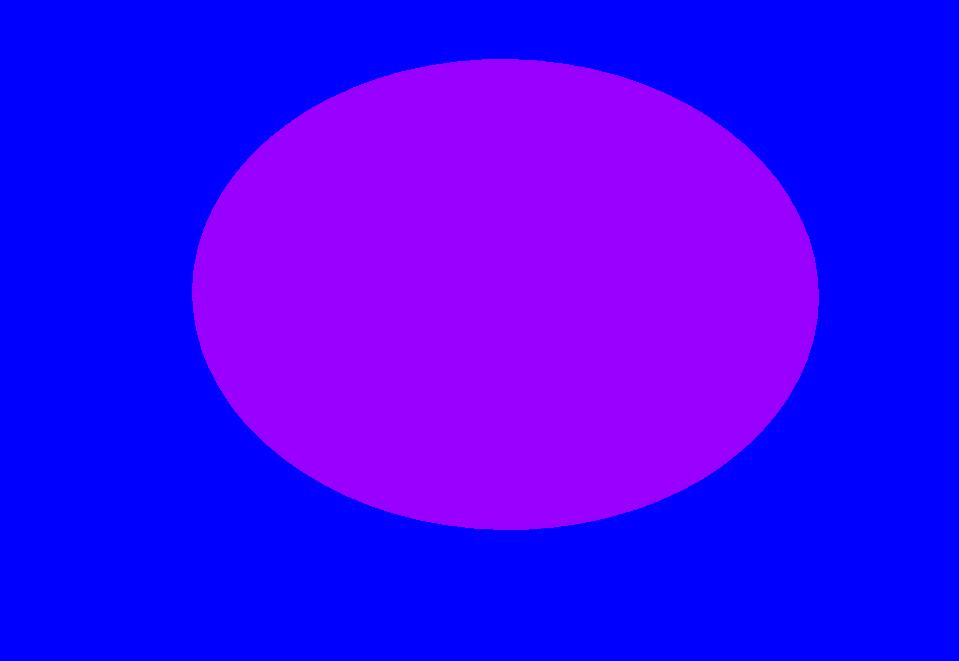

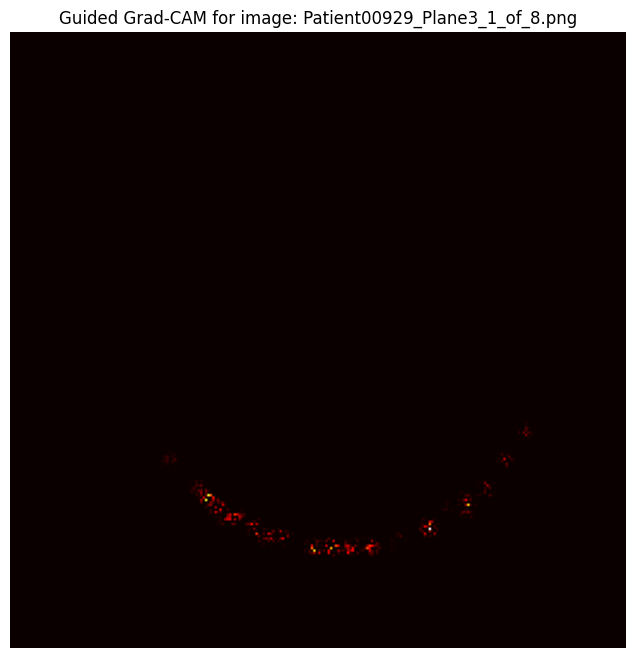

Guided Grad-CAM for image: Patient00929_Plane3_1_of_8.png


In [ ]:
# This cell combines all Grad-CAM and Guided Grad-CAM logic,
# including function definitions and their execution, to ensure all changes are applied.
# It will generate and display both Grad-CAM and Guided Grad-CAM for a random image.

# Define necessary imports (re-including them to ensure availability in this self-contained block)
import numpy as np
import tensorflow as tf
from tensorflow import keras
from IPython.display import Image, display
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import os

# Re-execute the definition of get_img_array (from cell ee973b83)
def get_img_array(img_path, size):
    img = keras.preprocessing.image.load_img(img_path, target_size=size)
    array = keras.preprocessing.image.img_to_array(img)
    array = array / 255.0
    array = np.expand_dims(array, axis=0)
    return array

# Re-execute the definition of save_and_display_gradcam (from cell 7cb4008e)
def save_and_display_gradcam(img_path, heatmap, alpha=0.4):
    img = keras.preprocessing.image.load_img(img_path)
    img = keras.preprocessing.image.img_to_array(img)
    img = img / 255.0
    heatmap_scaled_for_cmap = np.uint8(255 * heatmap)
    jet = cm.get_cmap("jet")
    jet_colors = jet(np.arange(256))[:, :3]
    jet_heatmap = jet_colors[heatmap_scaled_for_cmap]
    jet_heatmap = keras.preprocessing.image.array_to_img(jet_heatmap)
    jet_heatmap = jet_heatmap.resize((img.shape[1], img.shape[0]))
    jet_heatmap = keras.preprocessing.image.img_to_array(jet_heatmap)
    superimposed_img = jet_heatmap * alpha + img * (1 - alpha)
    superimposed_img = np.clip(superimposed_img, 0, 1)
    superimposed_img = keras.preprocessing.image.array_to_img(superimposed_img * 255.0)
    output_path = "gradcam_image.jpg"
    superimposed_img.save(output_path)
    display(Image(output_path))

# Re-execute the definition of make_gradcam_heatmap (from cell 7e799d27)
def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):
    grad_model = tf.keras.models.Model(
        model.input, [model.get_layer(last_conv_layer_name).output, model.output]
    )
    with tf.GradientTape() as tape:
        last_conv_layer_output, preds = grad_model(img_array)
        score = tf.reduce_mean(preds[0])
    grads = tape.gradient(score, last_conv_layer_output)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    last_conv_layer_output = last_conv_layer_output[0]
    heatmap = last_conv_layer_output @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    max_heatmap = tf.reduce_max(heatmap)
    if max_heatmap == 0:
        return np.zeros_like(heatmap.numpy())
    heatmap = tf.maximum(heatmap, 0) / (max_heatmap + tf.keras.backend.epsilon())
    return heatmap.numpy()

# --- Grad-CAM Execution ---

# Get a random image from the validation set
idx = np.random.randint(0, len(val_generator.image_filenames))
img_path_for_gradcam = val_generator.image_filenames[idx]

# Get an image array for the selected image
img_size = (256, 256) # Must match model's input size
img_array_for_gradcam = get_img_array(img_path_for_gradcam, size=img_size)

# The name of the last convolutional layer. This should be 'conv2d_17' for the current model.
last_conv_layer_name = "conv2d_17"

# Generate Grad-CAM heatmap
heatmap = make_gradcam_heatmap(img_array_for_gradcam, model, last_conv_layer_name)

# Display Grad-CAM
print(f"Grad-CAM for image: {os.path.basename(img_path_for_gradcam)}")
save_and_display_gradcam(img_path_for_gradcam, heatmap)

# --- Guided Grad-CAM Execution ---

# Calculate Guided Backprop gradients
with tf.GradientTape() as tape:
    img_tensor_for_gradcam = tf.constant(img_array_for_gradcam, dtype=tf.float32)
    tape.watch(img_tensor_for_gradcam)
    preds = model(img_tensor_for_gradcam)
    score = tf.reduce_mean(preds[0])

guided_grads = tape.gradient(score, img_tensor_for_gradcam)
guided_grads = guided_grads[0]

upsampled_heatmap = tf.image.resize(tf.expand_dims(heatmap, axis=-1), img_size)

guided_grads = tf.cast(guided_grads, tf.float32)
guided_grads = tf.maximum(guided_grads, 0)

guided_grad_cam = guided_grads * upsampled_heatmap

guided_grad_cam_display = guided_grad_cam.numpy()
min_val = guided_grad_cam_display.min()
max_val = guided_grad_cam_display.max()

if (max_val - min_val) == 0:
    guided_grad_cam_display = np.zeros_like(guided_grad_cam_display)
else:
    guided_grad_cam_display = (guided_grad_cam_display - min_val) / (max_val - min_val)

plt.figure(figsize=(8, 8))
plt.imshow(guided_grad_cam_display[..., 0], cmap='hot')
plt.title(f'Guided Grad-CAM for image: {os.path.basename(img_path_for_gradcam)}')
plt.axis('off')
plt.savefig("guided_gradcam_image.jpg")
plt.show()

print(f"Guided Grad-CAM for image: {os.path.basename(img_path_for_gradcam)}")

/usr/local/lib/python3.12/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor']
Received: inputs=Tensor(shape=(1, 256, 256, 3))
  warnings.warn(msg)


Grad-CAM for image: Patient01126_Plane3_3_of_5.png


/tmp/ipykernel_481/3508097698.py:29: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  jet = cm.get_cmap("jet")


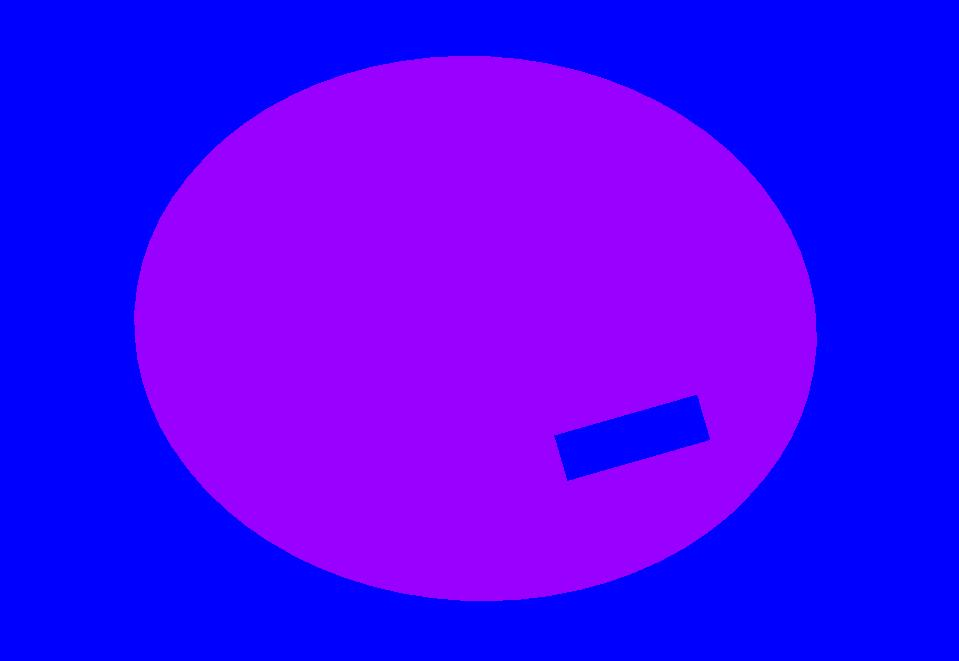

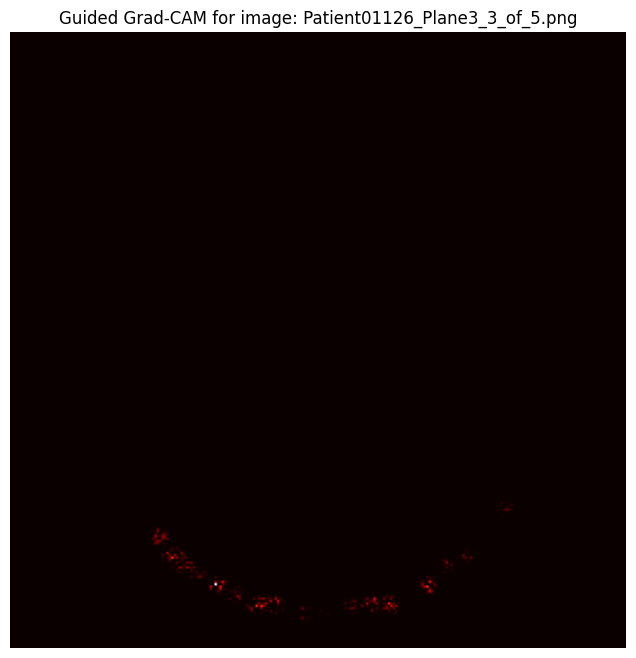

Guided Grad-CAM for image: Patient01126_Plane3_3_of_5.png


In [ ]:
# Execute the combined Grad-CAM and Guided Grad-CAM code with the latest fixes.
# This cell contains the re-definitions of helper functions and the visualization logic.
# All necessary imports are included at the top of this consolidated block.
# It will generate and display both Grad-CAM and Guided Grad-CAM for a random image.

# Define necessary imports that might be needed by the functions
import numpy as np
import tensorflow as tf
from tensorflow import keras
from IPython.display import Image, display
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import os

# Re-execute the definition of get_img_array to ensure it's up-to-date (from cell ee973b83)
def get_img_array(img_path, size):
    img = keras.preprocessing.image.load_img(img_path, target_size=size)
    array = keras.preprocessing.image.img_to_array(img)
    array = array / 255.0
    array = np.expand_dims(array, axis=0)
    return array

# Re-execute the definition of save_and_display_gradcam to ensure it's up-to-date (from cell 7cb4008e)
def save_and_display_gradcam(img_path, heatmap, alpha=0.4):
    img = keras.preprocessing.image.load_img(img_path)
    img = keras.preprocessing.image.img_to_array(img)
    img = img / 255.0
    heatmap_scaled_for_cmap = np.uint8(255 * heatmap)
    jet = cm.get_cmap("jet")
    jet_colors = jet(np.arange(256))[:, :3]
    jet_heatmap = jet_colors[heatmap_scaled_for_cmap]
    jet_heatmap = keras.preprocessing.image.array_to_img(jet_heatmap)
    jet_heatmap = jet_heatmap.resize((img.shape[1], img.shape[0]))
    jet_heatmap = keras.preprocessing.image.img_to_array(jet_heatmap)
    superimposed_img = jet_heatmap * alpha + img * (1 - alpha)
    superimposed_img = np.clip(superimposed_img, 0, 1)
    superimposed_img = keras.preprocessing.image.array_to_img(superimposed_img * 255.0)
    output_path = "gradcam_image.jpg"
    superimposed_img.save(output_path)
    display(Image(output_path))

# Re-execute the definition of make_gradcam_heatmap to ensure it's up-to-date (from cell 7e799d27)
def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):
    grad_model = tf.keras.models.Model(
        model.input, [model.get_layer(last_conv_layer_name).output, model.output]
    )
    with tf.GradientTape() as tape:
        last_conv_layer_output, preds = grad_model(img_array)
        score = tf.reduce_mean(preds[0])
    grads = tape.gradient(score, last_conv_layer_output)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    last_conv_layer_output = last_conv_layer_output[0]
    heatmap = last_conv_layer_output @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    max_heatmap = tf.reduce_max(heatmap)
    if max_heatmap == 0:
        return np.zeros_like(heatmap.numpy())
    heatmap = tf.maximum(heatmap, 0) / (max_heatmap + tf.keras.backend.epsilon())
    return heatmap.numpy()

# Get a few random indices from the validation set
idx = np.random.randint(0, len(val_generator.image_filenames))
img_path_for_gradcam = val_generator.image_filenames[idx]

# Get an image array for the selected image
img_size = (256, 256) # Must match model's input size
img_array_for_gradcam = get_img_array(img_path_for_gradcam, size=img_size)

# The name of the last convolutional layer.
last_conv_layer_name = "conv2d_17"

# Generate heatmap
heatmap = make_gradcam_heatmap(img_array_for_gradcam, model, last_conv_layer_name)

# Display Grad-CAM
print(f"Grad-CAM for image: {os.path.basename(img_path_for_gradcam)}")
save_and_display_gradcam(img_path_for_gradcam, heatmap)

# --- Guided Grad-CAM ---

# Calculate Guided Backprop gradients
with tf.GradientTape() as tape:
    img_tensor_for_gradcam = tf.constant(img_array_for_gradcam, dtype=tf.float32)
    tape.watch(img_tensor_for_gradcam)
    preds = model(img_tensor_for_gradcam)
    score = tf.reduce_mean(preds[0])

guided_grads = tape.gradient(score, img_tensor_for_gradcam)
guided_grads = guided_grads[0]

upsampled_heatmap = tf.image.resize(tf.expand_dims(heatmap, axis=-1), img_size)

guided_grads = tf.cast(guided_grads, tf.float32)
guided_grads = tf.maximum(guided_grads, 0)

guided_grad_cam = guided_grads * upsampled_heatmap

guided_grad_cam_display = guided_grad_cam.numpy()
min_val = guided_grad_cam_display.min()
max_val = guided_grad_cam_display.max()

if (max_val - min_val) == 0:
    guided_grad_cam_display = np.zeros_like(guided_grad_cam_display)
else:
    guided_grad_cam_display = (guided_grad_cam_display - min_val) / (max_val - min_val)

plt.figure(figsize=(8, 8))
plt.imshow(guided_grad_cam_display[..., 0], cmap='hot')
plt.title(f'Guided Grad-CAM for image: {os.path.basename(img_path_for_gradcam)}')
plt.axis('off')
plt.savefig("guided_gradcam_image.jpg")
plt.show()

print(f"Guided Grad-CAM for image: {os.path.basename(img_path_for_gradcam)}")

/usr/local/lib/python3.12/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor']
Received: inputs=Tensor(shape=(1, 256, 256, 3))
  warnings.warn(msg)


Grad-CAM for image: Patient00842_Plane3_2_of_2.png


/tmp/ipykernel_481/2132838226.py:25: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  jet = cm.get_cmap("jet")


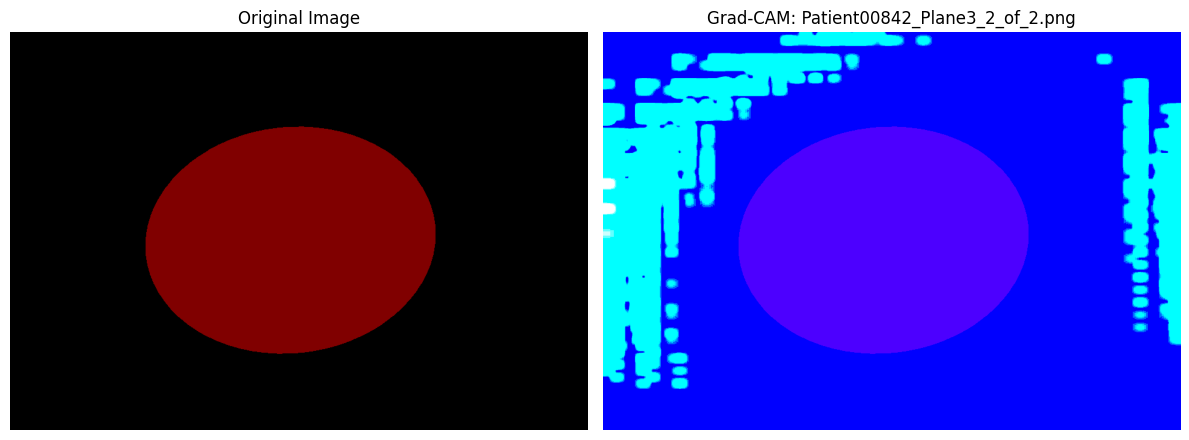

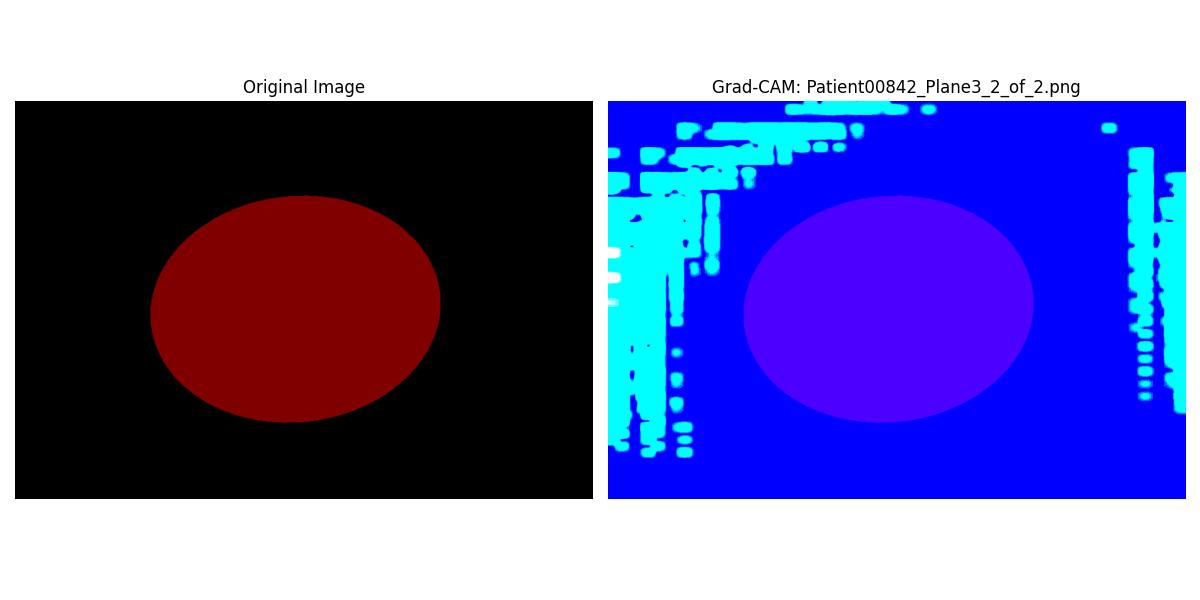

Guided Grad-CAM for image: Patient00842_Plane3_2_of_2.png


/tmp/ipykernel_481/2132838226.py:25: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  jet = cm.get_cmap("jet")


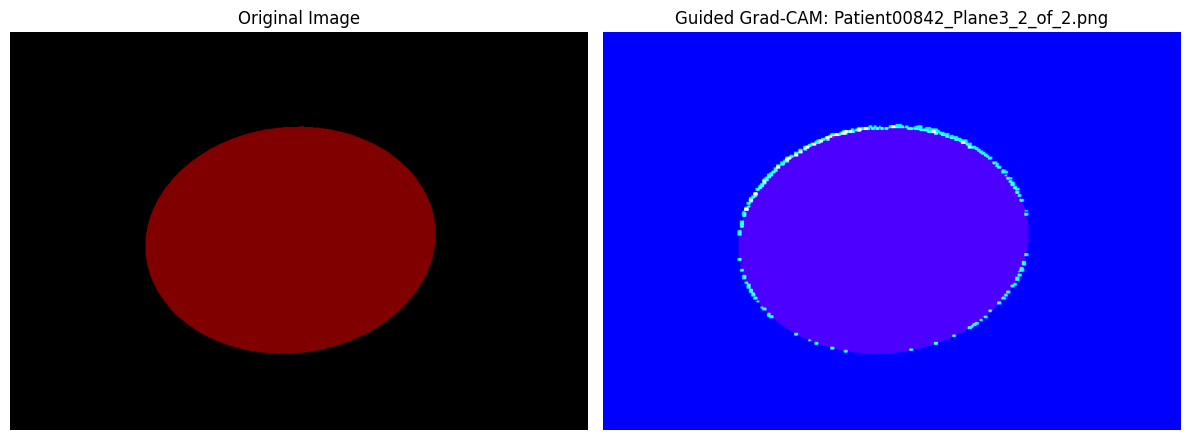

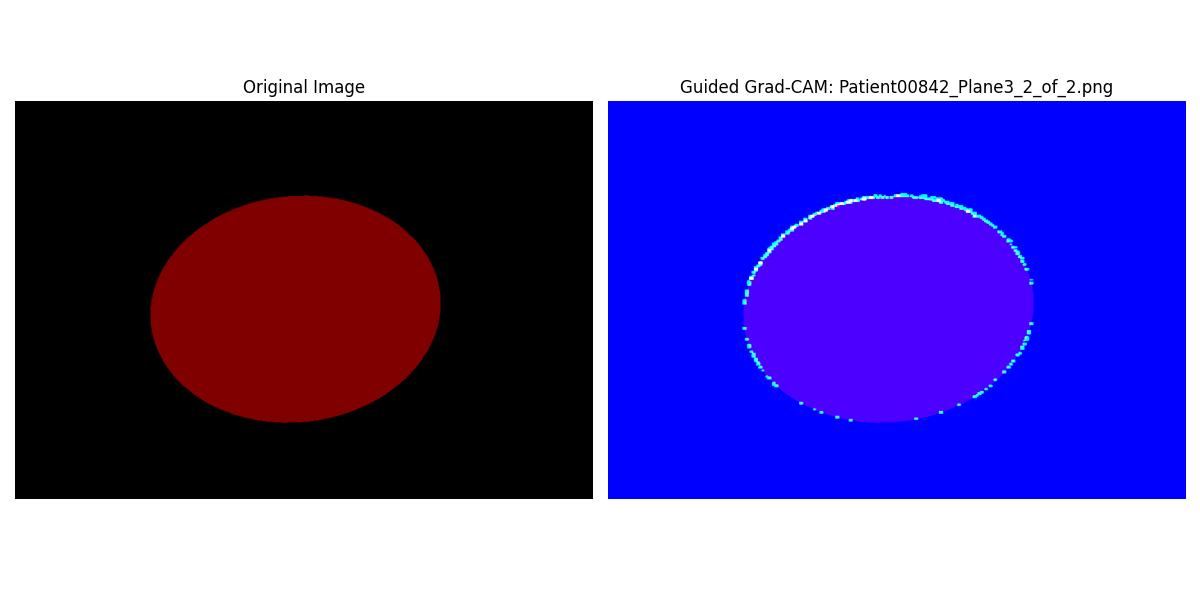

In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from IPython.display import Image, display
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import os

def get_img_array(img_path, size):
    img = keras.preprocessing.image.load_img(img_path, target_size=size)
    array = keras.preprocessing.image.img_to_array(img)
    array = array / 255.0
    array = np.expand_dims(array, axis=0)
    return array

def save_and_display_gradcam(img_path, heatmap, title_prefix="Grad-CAM", alpha=0.4):
    # Load the original image
    img = keras.preprocessing.image.load_img(img_path)
    original_img_array = keras.preprocessing.image.img_to_array(img) / 255.0 # Normalize for display

    # Rescale heatmap to a range 0-255 (temporarily for colormap application)
    heatmap_scaled_for_cmap = np.uint8(255 * heatmap)

    # Use jet colormap to colorize heatmap
    jet = cm.get_cmap("jet")

    # Use RGB values of the colormap
    jet_colors = jet(np.arange(256))[:, :3]
    jet_heatmap = jet_colors[heatmap_scaled_for_cmap]

    # Create an image with RGB colorized heatmap
    jet_heatmap = keras.preprocessing.image.array_to_img(jet_heatmap)
    jet_heatmap = jet_heatmap.resize((original_img_array.shape[1], original_img_array.shape[0]))
    jet_heatmap = keras.preprocessing.image.img_to_array(jet_heatmap)

    # Superimpose the heatmap on original image
    superimposed_img = jet_heatmap * alpha + original_img_array * (1 - alpha)
    superimposed_img = np.clip(superimposed_img, 0, 1)

    # Create a figure with two subplots: original image and superimposed Grad-CAM
    plt.figure(figsize=(12, 6))

    plt.subplot(1, 2, 1)
    plt.imshow(original_img_array)
    plt.title('Original Image')
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(superimposed_img)
    plt.title(f'{title_prefix}: {os.path.basename(img_path)}')
    plt.axis('off')

    plt.tight_layout()
    output_path = f"gradcam_image_{title_prefix.replace(' ', '_').lower()}.jpg"
    plt.savefig(output_path)
    plt.show()
    display(Image(output_path))

def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):
    grad_model = tf.keras.models.Model(
        model.input, [model.get_layer(last_conv_layer_name).output, model.output]
    )
    with tf.GradientTape() as tape:
        last_conv_layer_output, preds = grad_model(img_array)
        score = tf.reduce_mean(preds[0])
    grads = tape.gradient(score, last_conv_layer_output)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    last_conv_layer_output = last_conv_layer_output[0]
    heatmap = last_conv_layer_output @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    max_heatmap = tf.reduce_max(heatmap)
    if max_heatmap == 0:
        return np.zeros_like(heatmap.numpy())
    heatmap = tf.maximum(heatmap, 0) / (max_heatmap + tf.keras.backend.epsilon())
    return heatmap.numpy()

# --- Grad-CAM Execution ---

# Get a random image from the validation set
idx = np.random.randint(0, len(val_generator.image_filenames))
img_path_for_gradcam = val_generator.image_filenames[idx]

# Get an image array for the selected image
img_size = (256, 256) # Must match model's input size
img_array_for_gradcam = get_img_array(img_path_for_gradcam, size=img_size)

# The name of the last convolutional layer.
last_conv_layer_name = "conv2d_17"

# Generate heatmap
heatmap = make_gradcam_heatmap(img_array_for_gradcam, model, last_conv_layer_name)

# Display Grad-CAM
print(f"Grad-CAM for image: {os.path.basename(img_path_for_gradcam)}")
save_and_display_gradcam(img_path_for_gradcam, heatmap, title_prefix="Grad-CAM")

# --- Guided Grad-CAM Execution ---

# Calculate Guided Backprop gradients
with tf.GradientTape() as tape:
    img_tensor_for_gradcam = tf.constant(img_array_for_gradcam, dtype=tf.float32)
    tape.watch(img_tensor_for_gradcam)
    preds = model(img_tensor_for_gradcam)
    score = tf.reduce_mean(preds[0])

guided_grads = tape.gradient(score, img_tensor_for_gradcam)
guided_grads = guided_grads[0]

upsampled_heatmap = tf.image.resize(tf.expand_dims(heatmap, axis=-1), img_size)

guided_grads = tf.cast(guided_grads, tf.float32)
guided_grads = tf.maximum(guided_grads, 0)

guided_grad_cam = guided_grads * upsampled_heatmap

guided_grad_cam_display = guided_grad_cam.numpy()
min_val = guided_grad_cam_display.min()
max_val = guided_grad_cam_display.max()

if (max_val - min_val) == 0:
    guided_grad_cam_display = np.zeros_like(guided_grad_cam_display)
else:
    guided_grad_cam_display = (guided_grad_cam_display - min_val) / (max_val - min_val)

# Display Guided Grad-CAM using the modified function
print(f"Guided Grad-CAM for image: {os.path.basename(img_path_for_gradcam)}")
save_and_display_gradcam(img_path_for_gradcam, guided_grad_cam_display[:,:,0], title_prefix="Guided Grad-CAM")


Merged DataFrame head:


,image_filename,dice_coefficient,bce_loss
0,Patient01779_Plane3_1_of_4.png,0.425125,0.274525
1,Patient00695_Plane3_1_of_4.png,0.394673,0.228029
2,Patient01057_Plane3_1_of_3.png,0.412680,0.199520
3,Patient01051_Plane3_3_of_4.png,0.428978,0.310836
4,Patient01109_Plane3_1_of_1.png,0.373669,0.265950



Pearson correlation between BCE Loss and Dice Coefficient: -0.0830


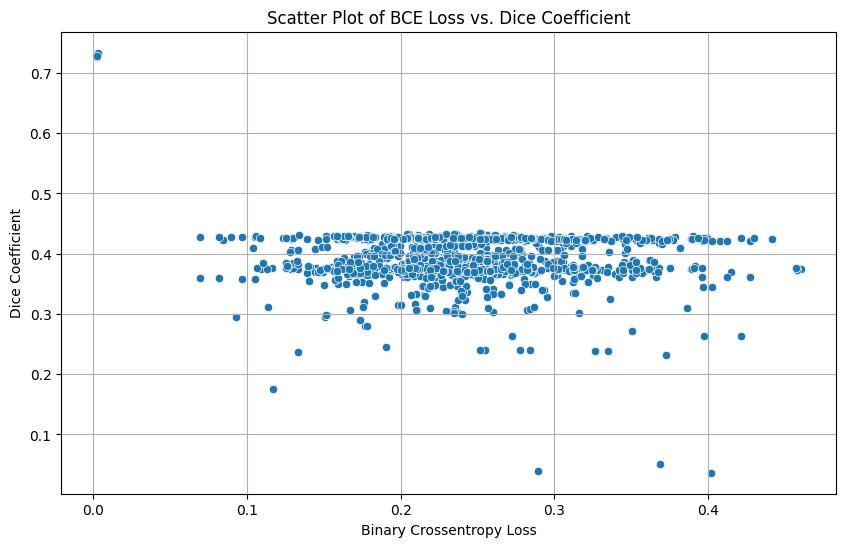

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Merge the two dataframes on 'image_filename'
correlation_df = pd.merge(dice_df, bce_df, on='image_filename')

print("Merged DataFrame head:")
display(correlation_df.head())

# Calculate the Pearson correlation coefficient
correlation = correlation_df['bce_loss'].corr(correlation_df['dice_coefficient'])

print(f"\nPearson correlation between BCE Loss and Dice Coefficient: {correlation:.4f}")

# Visualize the correlation with a scatter plot
plt.figure(figsize=(10, 6))
sns.scatterplot(x='bce_loss', y='dice_coefficient', data=correlation_df)
plt.title('Scatter Plot of BCE Loss vs. Dice Coefficient')
plt.xlabel('Binary Crossentropy Loss')
plt.ylabel('Dice Coefficient')
plt.grid(True)
plt.show()

In [ ]:
from scipy.spatial.distance import directed_hausdorff
import pandas as pd
import numpy as np
import os

hausdorff_distances = []

print("Calculating Hausdorff distances for validation set...")

# Iterate through the validation generator
for i in range(len(val_generator)):
    X_batch, y_batch = val_generator[i]

    # Make prediction for the batch
    predictions = model.predict(X_batch, verbose=0)
    predicted_masks_final = predictions[0] # Get the final_output predictions

    # Get true masks for the batch (final_output)
    true_masks_final = y_batch['final_output']

    for j in range(X_batch.shape[0]): # Iterate through samples in the batch
        # Get original image filename
        original_idx = val_generator.indexes[i * val_generator.batch_size + j]
        image_filename = os.path.basename(val_generator.image_filenames[original_idx])

        true_mask_raw = true_masks_final[j]
        predicted_mask_raw = predicted_masks_final[j]

        # Binarize predicted mask and squeeze for 2D processing
        true_mask_binary = (true_mask_raw > 0.5).astype(bool).squeeze() # Ensure boolean for argwhere
        predicted_mask_binary = (predicted_mask_raw > 0.5).astype(bool).squeeze()

        # Extract coordinates of foreground pixels
        coords_true = np.argwhere(true_mask_binary)
        coords_pred = np.argwhere(predicted_mask_binary)

        hd = np.nan # Initialize Hausdorff distance as NaN

        if coords_true.size == 0 and coords_pred.size == 0:
            hd = 0.0 # Both masks are empty, distance is 0
        elif coords_true.size == 0 or coords_pred.size == 0:
            # One mask is empty and the other is not, Hausdorff distance is infinite
            hd = np.inf
        else:
            # Calculate directed Hausdorff distance in both directions
            # and take the maximum for the undirected Hausdorff distance
            try:
                hd1 = directed_hausdorff(coords_true, coords_pred)[0]
                hd2 = directed_hausdorff(coords_pred, coords_true)[0]
                hd = max(hd1, hd2)
            except Exception as e:
                print(f"Error calculating Hausdorff for {image_filename}: {e}")
                hd = np.nan # Assign NaN if an error occurs

        hausdorff_distances.append({
            'image_filename': image_filename,
            'hausdorff_distance': hd
        })

print("Hausdorff distance calculation complete.")

# Convert to DataFrame and display
hausdorff_df = pd.DataFrame(hausdorff_distances)
csv_filename_hd = 'validation_hausdorff_distances.csv'
hausdorff_df.to_csv(csv_filename_hd, index=False)

print(f"Hausdorff distances saved to {csv_filename_hd}")
display(hausdorff_df.head())

Calculating Hausdorff distances for validation set...
Hausdorff distance calculation complete.
Hausdorff distances saved to validation_hausdorff_distances.csv


,image_filename,hausdorff_distance
0,Patient01779_Plane3_1_of_4.png,97.498718
1,Patient00695_Plane3_1_of_4.png,inf
2,Patient01057_Plane3_1_of_3.png,inf
3,Patient01051_Plane3_3_of_4.png,109.444050
4,Patient01109_Plane3_1_of_1.png,inf


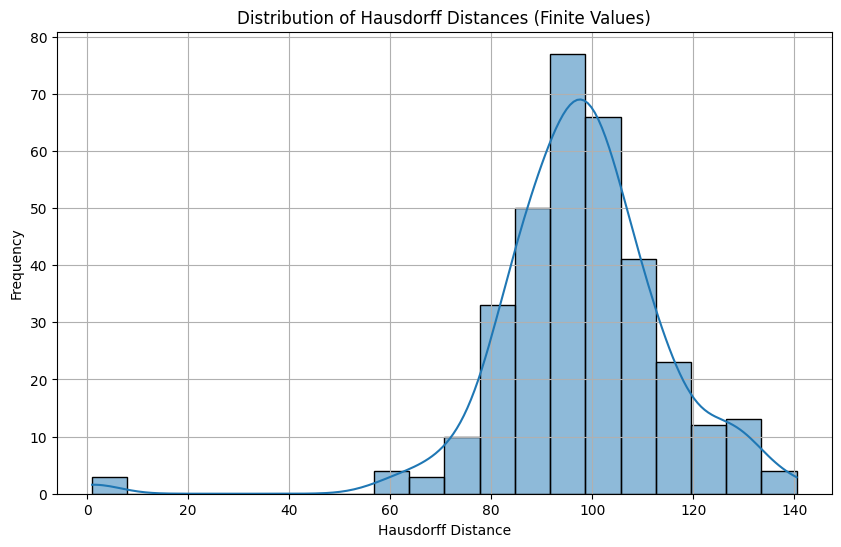


Hausdorff Distance Summary Statistics:
count    936.000000
mean            inf
std             NaN
min        1.000000
25%      104.259244
50%             NaN
75%             NaN
max             inf
Name: hausdorff_distance, dtype: float64
Number of infinite Hausdorff distances: 597 (indicating one mask was empty)


/usr/local/lib/python3.12/dist-packages/numpy/lib/_function_base_impl.py:4779: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Filter out infinite values for plotting, as they can distort the visualization
hausdorff_finite = hausdorff_df[np.isfinite(hausdorff_df['hausdorff_distance'])]

plt.figure(figsize=(10, 6))
sns.histplot(hausdorff_finite['hausdorff_distance'], bins=20, kde=True)
plt.title('Distribution of Hausdorff Distances (Finite Values)')
plt.xlabel('Hausdorff Distance')
plt.ylabel('Frequency')
plt.grid(True)
plt.show()

# Also, print summary statistics including handling of infinite values
print("\nHausdorff Distance Summary Statistics:")
print(hausdorff_df['hausdorff_distance'].describe())

num_infinite_hd = hausdorff_df['hausdorff_distance'].isin([np.inf, -np.inf]).sum()
if num_infinite_hd > 0:
    print(f"Number of infinite Hausdorff distances: {num_infinite_hd} (indicating one mask was empty)")

In [ ]:
import pandas as pd
import numpy as np
import os
from tensorflow.keras import backend as K
import tensorflow as tf

# IoU (Intersection over Union) Calculation
# We will use the definition: IoU = (Intersection) / (Union)
def iou_score(y_true, y_pred):
    y_true_f = tf.cast(K.flatten(y_true), tf.float32) # Explicitly cast to float32
    y_pred_f = tf.cast(K.flatten(y_pred), tf.float32) # Explicitly cast to float32

    intersection = K.sum(y_true_f * y_pred_f)
    union = K.sum(y_true_f) + K.sum(y_pred_f) - intersection

    # Add epsilon to avoid division by zero
    return (intersection + K.epsilon()) / (union + K.epsilon())

image_ious = []

print("Calculating IoU scores for validation set...")

for i in range(len(val_generator)):
    X_batch, y_batch = val_generator[i]

    predictions = model.predict(X_batch, verbose=0)
    predicted_masks_final = predictions[0] # Get the final_output predictions

    true_masks_final = y_batch['final_output']

    for j in range(X_batch.shape[0]):
        original_idx = val_generator.indexes[i * val_generator.batch_size + j]
        image_filename = os.path.basename(val_generator.image_filenames[original_idx])

        true_mask = true_masks_final[j]
        predicted_mask = (predicted_masks_final[j] > 0.5).astype(np.float32) # Binarize predicted mask

        score = K.eval(iou_score(true_mask, predicted_mask))

        image_ious.append({
            'image_filename': image_filename,
            'iou_score': score
        })

print("IoU score calculation complete.")

iou_df = pd.DataFrame(image_ious)
csv_filename_iou = 'validation_iou_scores.csv'
iou_df.to_csv(csv_filename_iou, index=False)

print(f"IoU scores saved to {csv_filename_iou}")
display(iou_df.head())

Calculating IoU scores for validation set...
IoU score calculation complete.
IoU scores saved to validation_iou_scores.csv


,image_filename,iou_score
0,Patient01779_Plane3_1_of_4.png,0.269942
1,Patient00695_Plane3_1_of_4.png,0.245852
2,Patient01057_Plane3_1_of_3.png,0.259985
3,Patient01051_Plane3_3_of_4.png,0.273057
4,Patient01109_Plane3_1_of_1.png,0.229762


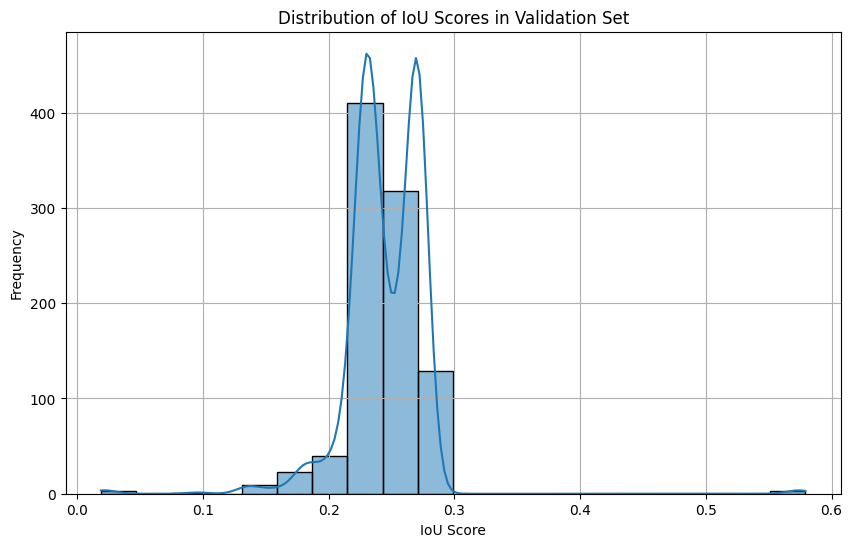


IoU Score Summary Statistics:
count    936.000000
mean       0.244587
std        0.034199
min        0.018625
25%        0.229144
50%        0.240587
75%        0.269645
max        0.579235
Name: iou_score, dtype: float64


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.histplot(iou_df['iou_score'], bins=20, kde=True)
plt.title('Distribution of IoU Scores in Validation Set')
plt.xlabel('IoU Score')
plt.ylabel('Frequency')
plt.grid(True)
plt.show()

print("\nIoU Score Summary Statistics:")
print(iou_df['iou_score'].describe())

In [ ]:
import numpy as np
import pandas as pd
import os
from scipy.ndimage import binary_erosion, binary_dilation

# Helper function to extract the boundary of a binary mask
def _extract_border(mask, width=1):
    # Ensure mask is boolean
    mask = mask.astype(bool)

    # Erode and dilate the mask
    eroded_mask = binary_erosion(mask, iterations=width)
    dilated_mask = binary_dilation(mask, iterations=width)

    # The border is the difference between the dilated and eroded mask
    border = np.logical_xor(dilated_mask, eroded_mask)
    return border

def calculate_boundary_f_score(y_true, y_pred, delta=1.0, width=1):
    """
    Calculates the Boundary F-score between two binary masks.

    Args:
        y_true (np.ndarray): The ground truth binary mask (H, W).
        y_pred (np.ndarray): The predicted binary mask (H, W).
        delta (float): The tolerance distance for considering points as true/false positives.
        width (int): The width of the boundary extracted using morphological operations.

    Returns:
        float: The Boundary F-score.
    """
    if y_true.sum() == 0 and y_pred.sum() == 0:
        return 1.0 # Perfect score if both are empty
    if y_true.sum() == 0 or y_pred.sum() == 0:
        return 0.0 # Zero score if one is empty and the other is not

    # Ensure masks are binary (0 or 1)
    y_true = (y_true > 0.5).astype(np.uint8)
    y_pred = (y_pred > 0.5).astype(np.uint8)

    # Extract boundaries
    true_border = _extract_border(y_true, width=width)
    pred_border = _extract_border(y_pred, width=width)

    # Get coordinates of border points
    coords_true = np.argwhere(true_border)
    coords_pred = np.argwhere(pred_border)

    if coords_true.size == 0 or coords_pred.size == 0:
        return 0.0 # No boundary points to compare

    # Calculate distances
    # For each true border point, find the closest predicted border point
    distances_true_to_pred = np.min(np.linalg.norm(coords_true[:, None, :] - coords_pred[None, :, :], axis=2), axis=1)
    # For each predicted border point, find the closest true border point
    distances_pred_to_true = np.min(np.linalg.norm(coords_pred[:, None, :] - coords_true[None, :, :], axis=2), axis=1)

    # Count true positives for precision and recall
    # A true boundary point is 'matched' if it's within delta of a predicted boundary point
    tp_true = np.sum(distances_true_to_pred <= delta)
    tp_pred = np.sum(distances_pred_to_true <= delta)

    # Recall: proportion of true boundary points detected by predicted boundary
    recall = tp_true / len(coords_true)

    # Precision: proportion of predicted boundary points that match a true boundary
    precision = tp_pred / len(coords_pred)

    # Calculate F-score
    if (precision + recall) == 0:
        return 0.0
    f_score = 2 * (precision * recall) / (precision + recall)
    return f_score


# List to store Boundary F-scores
boundary_f_scores = []

print("Calculating Boundary F-scores for validation set...")

# Iterate through the validation generator
for i in range(len(val_generator)):
    X_batch, y_batch = val_generator[i]

    # Make prediction for the batch
    predictions = model.predict(X_batch, verbose=0)
    predicted_masks_final = predictions[0] # Get the final_output predictions

    # Get true masks for the batch (final_output)
    true_masks_final = y_batch['final_output']

    for j in range(X_batch.shape[0]): # Iterate through samples in the batch
        # Get original image filename
        original_idx = val_generator.indexes[i * val_generator.batch_size + j]
        image_filename = os.path.basename(val_generator.image_filenames[original_idx])

        true_mask = true_masks_final[j].squeeze() # Remove channel dimension
        predicted_mask = (predicted_masks_final[j] > 0.5).astype(np.uint8).squeeze() # Binarize and remove channel dimension

        bf_score = calculate_boundary_f_score(true_mask, predicted_mask, delta=2.0, width=1) # Using a delta of 2 pixels

        boundary_f_scores.append({
            'image_filename': image_filename,
            'boundary_f_score': bf_score
        })

print("Boundary F-score calculation complete.")

# Convert to DataFrame and save to CSV
bf_df = pd.DataFrame(boundary_f_scores)
csv_filename_bf = 'validation_boundary_f_scores.csv'
bf_df.to_csv(csv_filename_bf, index=False)

print(f"Boundary F-scores saved to {csv_filename_bf}")
display(bf_df.head())

Calculating Boundary F-scores for validation set...
Boundary F-score calculation complete.
Boundary F-scores saved to validation_boundary_f_scores.csv


,image_filename,boundary_f_score
0,Patient01779_Plane3_1_of_4.png,0.016927
1,Patient00695_Plane3_1_of_4.png,0.000000
2,Patient01057_Plane3_1_of_3.png,0.000000
3,Patient01051_Plane3_3_of_4.png,0.019807
4,Patient01109_Plane3_1_of_1.png,0.000000


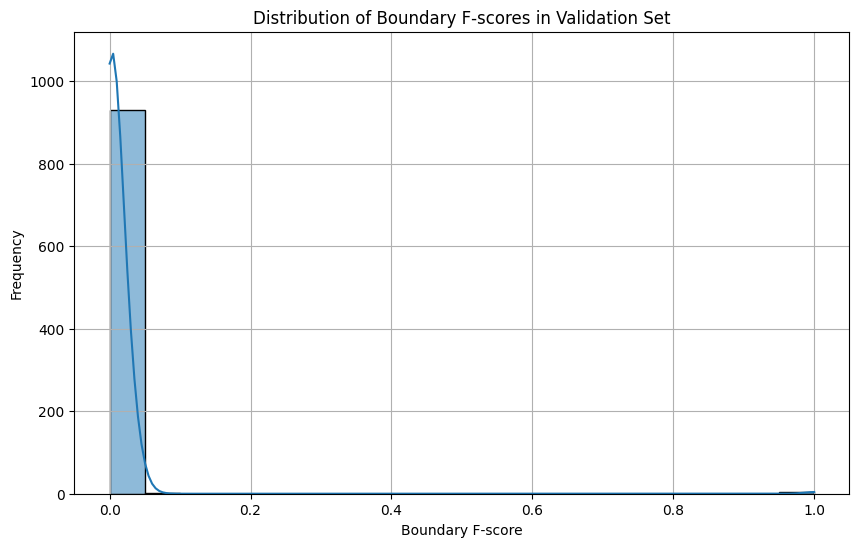


Boundary F-score Summary Statistics:
count    936.000000
mean       0.009911
std        0.057156
min        0.000000
25%        0.000000
50%        0.000000
75%        0.013007
max        1.000000
Name: boundary_f_score, dtype: float64


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Plotting the distribution of Boundary F-scores
plt.figure(figsize=(10, 6))
sns.histplot(bf_df['boundary_f_score'], bins=20, kde=True)
plt.title('Distribution of Boundary F-scores in Validation Set')
plt.xlabel('Boundary F-score')
plt.ylabel('Frequency')
plt.grid(True)
plt.show()

print("\nBoundary F-score Summary Statistics:")
print(bf_df['boundary_f_score'].describe())

Final Merged DataFrame Head:


,image_filename,dice_coefficient,bce_loss,hausdorff_distance,iou_score,boundary_f_score
0,Patient01779_Plane3_1_of_4.png,0.425125,0.274525,97.498718,0.269942,0.016927
1,Patient00695_Plane3_1_of_4.png,0.394673,0.228029,inf,0.245852,0.000000
2,Patient01057_Plane3_1_of_3.png,0.412680,0.199520,inf,0.259985,0.000000
3,Patient01051_Plane3_3_of_4.png,0.428978,0.310836,109.444050,0.273057,0.019807
4,Patient01109_Plane3_1_of_1.png,0.373669,0.265950,inf,0.229762,0.000000



Final Merged DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8616 entries, 0 to 8615
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   image_filename      8616 non-null   object 
 1   dice_coefficient    8616 non-null   float32
 2   bce_loss            8616 non-null   float32
 3   hausdorff_distance  8616 non-null   float64
 4   iou_score           8616 non-null   float32
 5   boundary_f_score    8616 non-null   float64
dtypes: float32(3), float64(2), object(1)
memory usage: 303.0+ KB


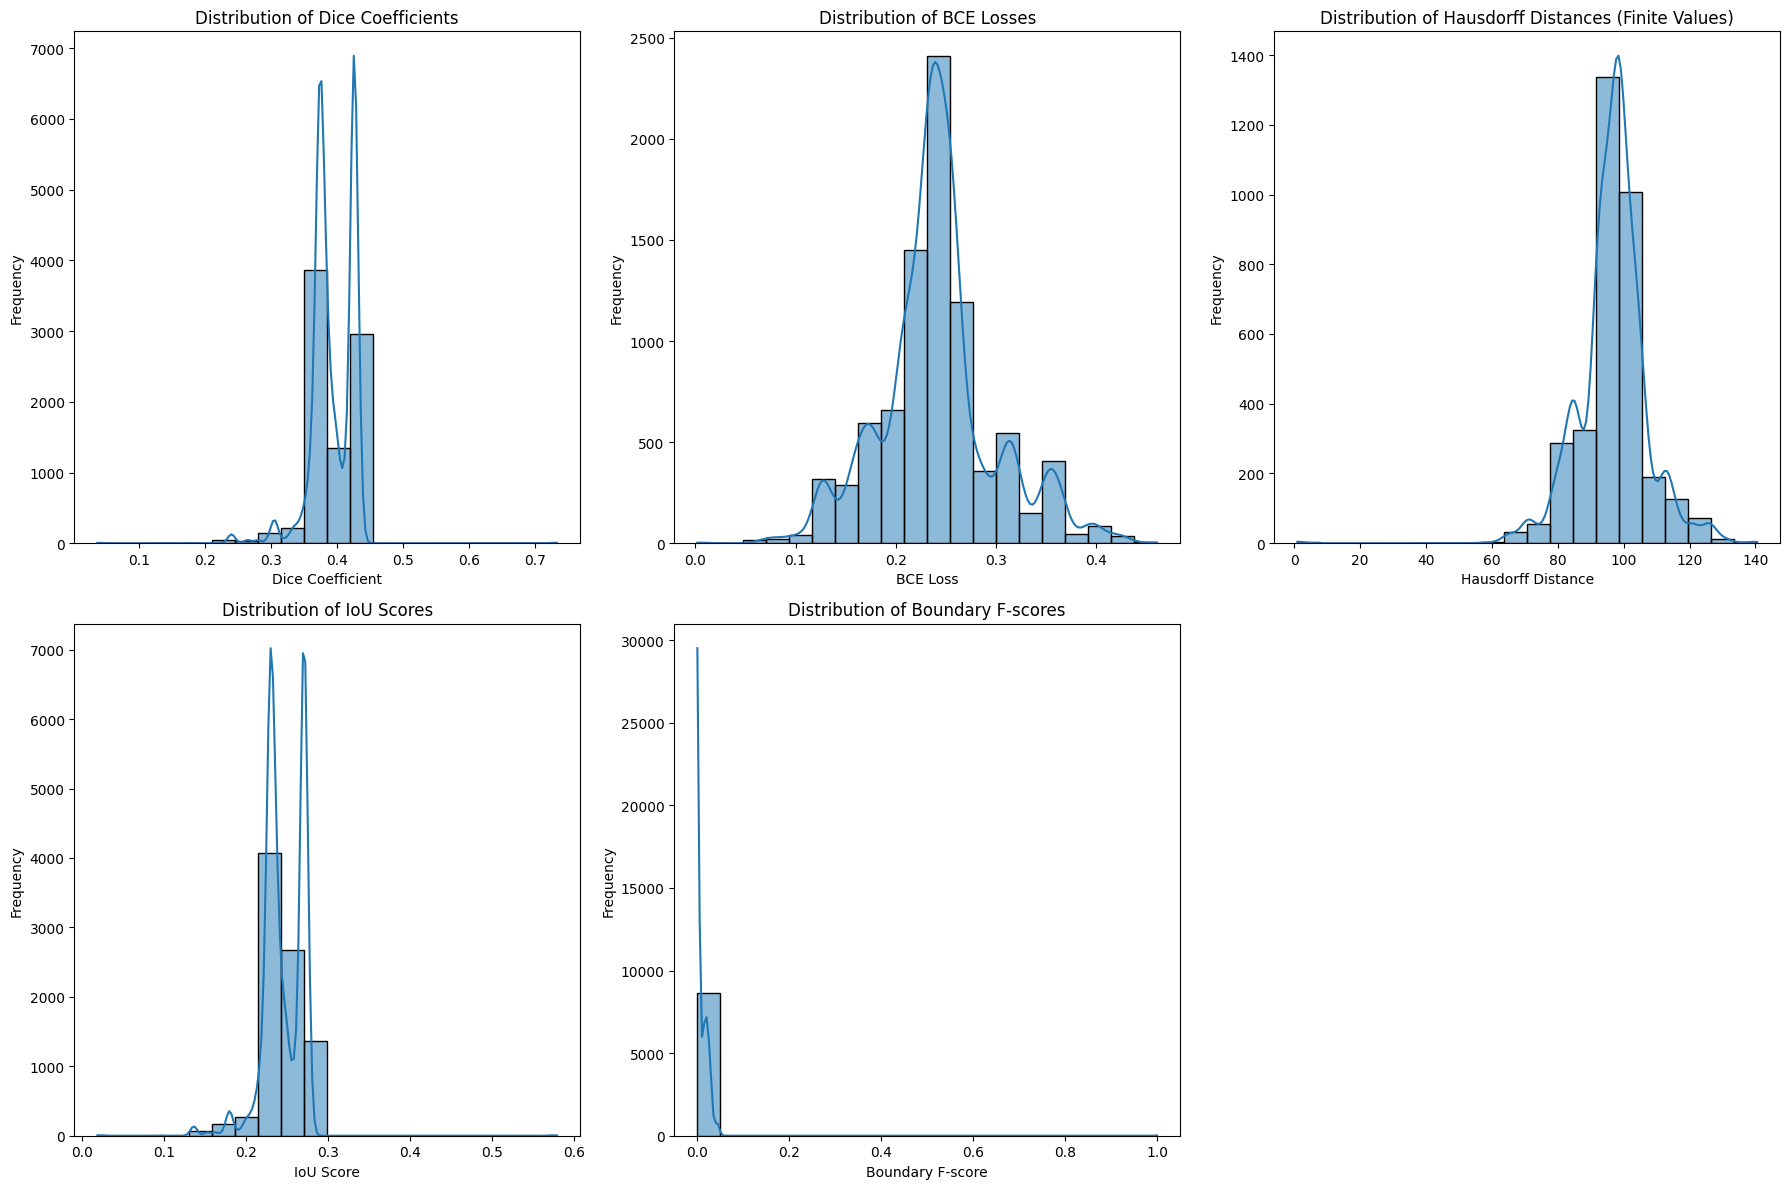


Pairplot of key metrics:


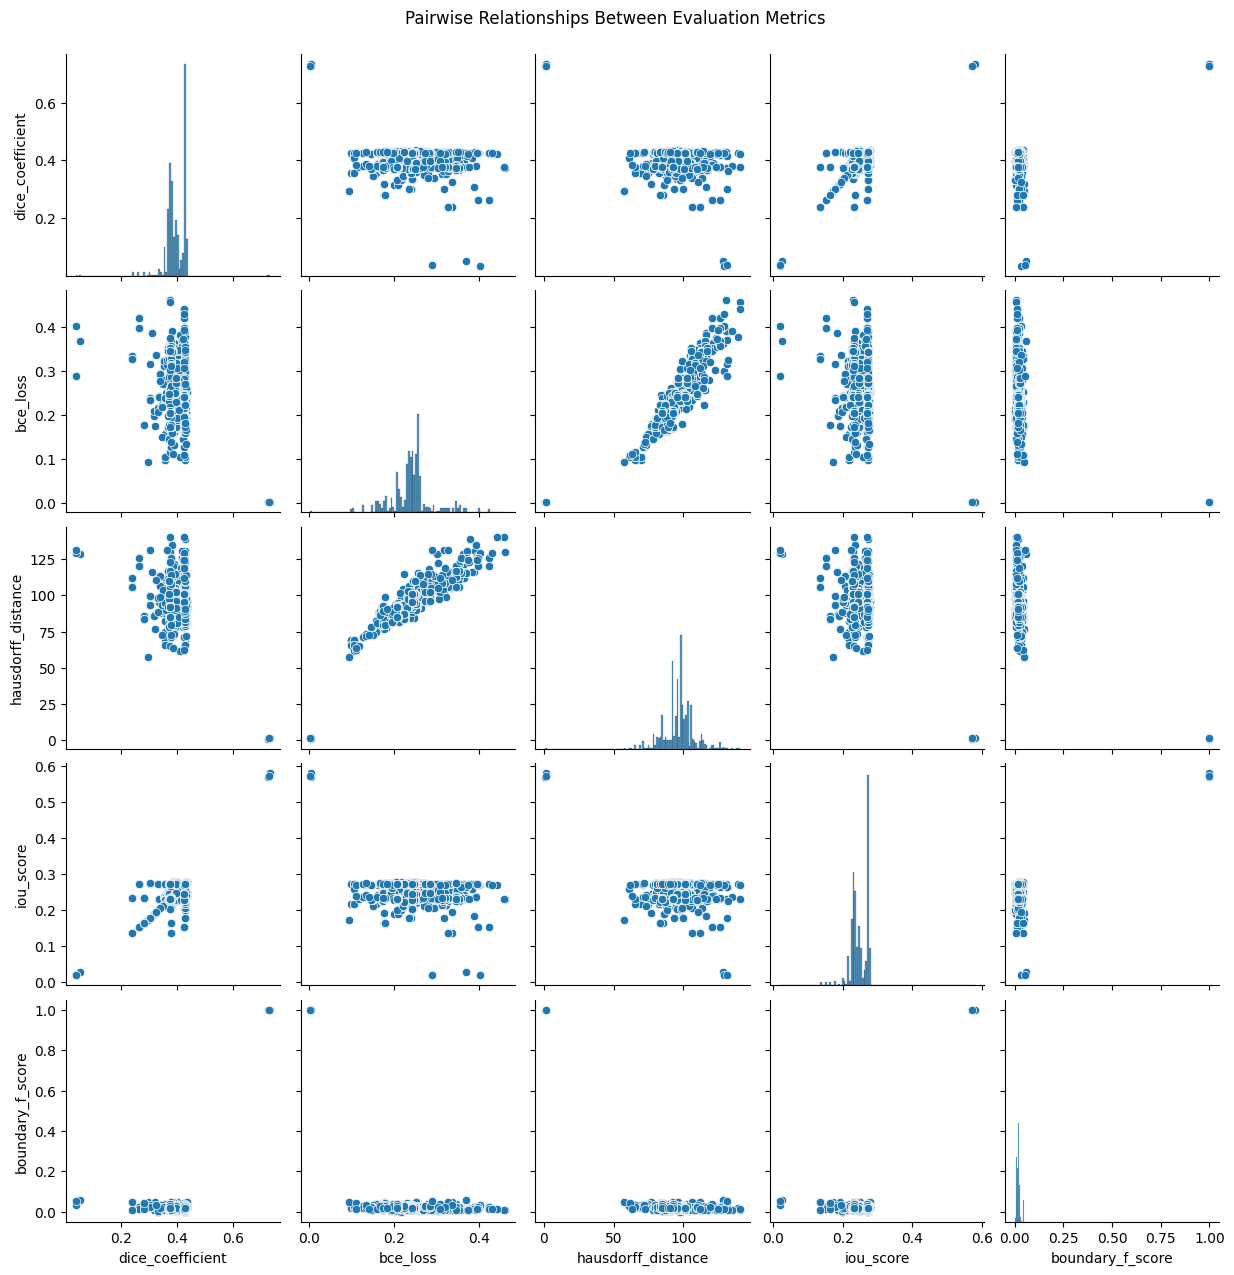


Correlation Heatmap of key metrics:


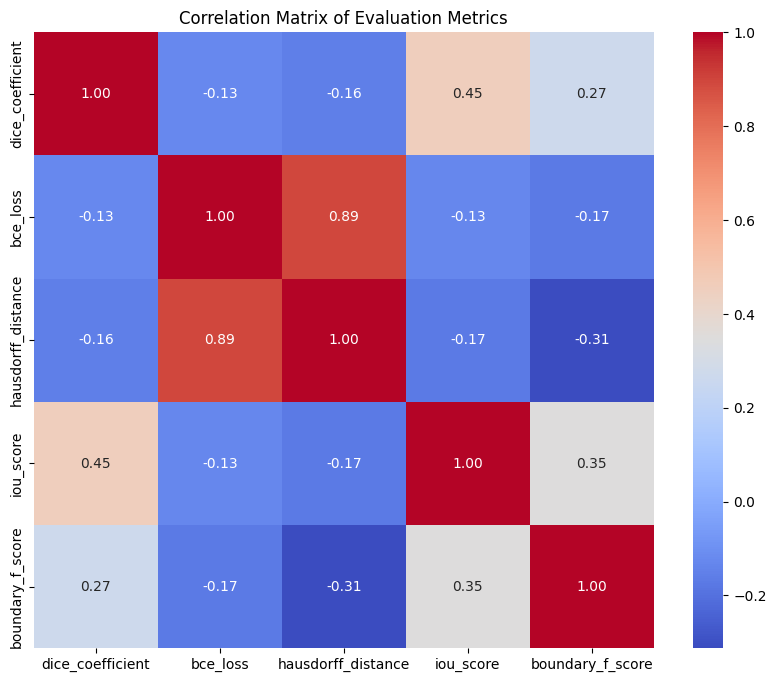


Summary Statistics for All Metrics:


/usr/local/lib/python3.12/dist-packages/numpy/lib/_function_base_impl.py:4779: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)


,dice_coefficient,bce_loss,hausdorff_distance,iou_score,boundary_f_score
count,8616.000000,8616.000000,8616.00000,8616.000000,8616.000000
mean,0.392456,0.241010,inf,0.244648,0.008258
std,0.032916,0.057115,NaN,0.025141,0.021647
min,0.036568,0.002111,1.00000,0.018625,0.000000
25%,0.373328,0.210434,98.73196,0.229504,0.000000
50%,0.385199,0.237883,NaN,0.238543,0.000000
75%,0.425015,0.259468,NaN,0.269853,0.016224
max,0.733564,0.460483,inf,0.579235,1.000000


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

# --- Merge all dataframes ---
# Start with dice_df
final_metrics_df = dice_df.copy()

# Merge with BCE scores
final_metrics_df = pd.merge(final_metrics_df, bce_df, on='image_filename', how='left')

# Merge with Hausdorff distances, handling potential infinite values for plotting
final_metrics_df = pd.merge(final_metrics_df, hausdorff_df, on='image_filename', how='left')

# Merge with IoU scores
final_metrics_df = pd.merge(final_metrics_df, iou_df, on='image_filename', how='left')

# Merge with Boundary F-scores
final_metrics_df = pd.merge(final_metrics_df, bf_df, on='image_filename', how='left')

print("Final Merged DataFrame Head:")
display(final_metrics_df.head())

print("\nFinal Merged DataFrame Info:")
final_metrics_df.info()

# --- Visualize Distributions of All Metrics ---
plt.figure(figsize=(18, 12))

plt.subplot(2, 3, 1)
sns.histplot(final_metrics_df['dice_coefficient'], bins=20, kde=True)
plt.title('Distribution of Dice Coefficients')
plt.xlabel('Dice Coefficient')
plt.ylabel('Frequency')

plt.subplot(2, 3, 2)
sns.histplot(final_metrics_df['bce_loss'], bins=20, kde=True)
plt.title('Distribution of BCE Losses')
plt.xlabel('BCE Loss')
plt.ylabel('Frequency')

plt.subplot(2, 3, 3)
# Filter out infinite Hausdorff distances for plotting
finite_hd_df = final_metrics_df[np.isfinite(final_metrics_df['hausdorff_distance'])]
sns.histplot(finite_hd_df['hausdorff_distance'], bins=20, kde=True)
plt.title('Distribution of Hausdorff Distances (Finite Values)')
plt.xlabel('Hausdorff Distance')
plt.ylabel('Frequency')

plt.subplot(2, 3, 4)
sns.histplot(final_metrics_df['iou_score'], bins=20, kde=True)
plt.title('Distribution of IoU Scores')
plt.xlabel('IoU Score')
plt.ylabel('Frequency')

plt.subplot(2, 3, 5)
sns.histplot(final_metrics_df['boundary_f_score'], bins=20, kde=True)
plt.title('Distribution of Boundary F-scores')
plt.xlabel('Boundary F-score')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

# --- Correlation Analysis (Pairplot) ---
print("\nPairplot of key metrics:")
# Create a subset dataframe for pairplot, excluding image_filename and infinite Hausdorff
metrics_for_correlation = final_metrics_df.drop(columns=['image_filename']).replace([np.inf, -np.inf], np.nan).dropna()

sns.pairplot(metrics_for_correlation)
plt.suptitle('Pairwise Relationships Between Evaluation Metrics', y=1.02)
plt.show()

# --- Correlation Heatmap ---
print("\nCorrelation Heatmap of key metrics:")
plt.figure(figsize=(10, 8))
sns.heatmap(metrics_for_correlation.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix of Evaluation Metrics')
plt.show()

print("\nSummary Statistics for All Metrics:")
display(final_metrics_df.describe())

In [ ]:
print("\nContents of /content/dataset/Trans-cerebellum/Trans-cerebellum/")
!ls -F /content/dataset/Trans-cerebellum/Trans-cerebellum/

print("\nContents of /content/dataset/Trans-ventricular/Trans-ventricular/")
!ls -F /content/dataset/Trans-ventricular/Trans-ventricular/

print("\nContents of /content/dataset/Diverse Fetal Head Images/Diverse Fetal Head Images/")
!ls -F "/content/dataset/Diverse Fetal Head Images/Diverse Fetal Head Images/"


Contents of /content/dataset/Trans-cerebellum/Trans-cerebellum/
Trans-cerebellum/			 Trans-cerebellum-OpenImage.zip
Trans-cerebellum-Cityscapes.zip		 Trans-cerebellum-PASCAL.zip
Trans-cerebellum-COCO.zip		 Trans-cerebellum-Pixel-Size.csv
Trans-cerebellum-CVAT.zip		 Trans-cerebellum-Segmentation.zip
Trans-cerebellum-Datumaro.zip		 Trans-cerebellum-TFRecord.zip
Trans-cerebellum-ICDAR-Localization.zip  Trans-cerebellum-YOLO.zip
Trans-cerebellum-LabelMe.zip

Contents of /content/dataset/Trans-ventricular/Trans-ventricular/
 Trans-ventricular/
 Trans-ventricular-CityScapes.zip
 Trans-ventricular-COCO.zip
 Trans-ventricular-CVAT.zip
 Trans-ventricular-Datumaro.zip
 Trans-ventricular-ICDAR-Localization.zip
 Trans-ventricular-LabelMe.zip
 Trans-ventricular-Open-Images.zip
'Trans-ventricular-PASCAL-VOC .zip'
 Trans-ventricular-Pixel-Size.csv
 Trans-ventricular-segmentation-mask.zip
 Trans-ventricular-TFRecord.zip
 Trans-ventricular-YOLO-1.1-.zip

Contents of /content/dataset/Diverse Fetal Head

In [ ]:
import zipfile
import os

dataset_root = '/content/dataset/'

# --- Step 1: Inspect 'Diverse Fetal Head Images' original image directory ---
print("\nContents of /content/dataset/Diverse Fetal Head Images/Diverse Fetal Head Images/Orginal_train_images_to_959_661/")
!ls -F "/content/dataset/Diverse Fetal Head Images/Diverse Fetal Head Images/Orginal_train_images_to_959_661/"

# --- Step 2: Unzip remaining segmentation masks ---

# Trans-cerebellum Segmentation
trans_cerebellum_segmentation_zip = os.path.join(dataset_root, 'Trans-cerebellum', 'Trans-cerebellum', 'Trans-cerebellum-Segmentation.zip')
trans_cerebellum_extract_path = os.path.join(dataset_root, 'Trans-cerebellum', 'Trans-cerebellum', 'Trans-cerebellum-Segmentation')

if os.path.exists(trans_cerebellum_segmentation_zip):
    print(f"\nUnzipping '{os.path.basename(trans_cerebellum_segmentation_zip)}' to '{trans_cerebellum_extract_path}'...")
    os.makedirs(trans_cerebellum_extract_path, exist_ok=True)
    with zipfile.ZipFile(trans_cerebellum_segmentation_zip, 'r') as zip_ref:
        zip_ref.extractall(trans_cerebellum_extract_path)
    print("Extraction complete.")
    print(f"Contents of {trans_cerebellum_extract_path}:")
    !ls -F "{trans_cerebellum_extract_path}" # Quoting added here
else:
    print(f"\nWarning: {os.path.basename(trans_cerebellum_segmentation_zip)} not found.")

# Trans-ventricular Segmentation
trans_ventricular_segmentation_zip = os.path.join(dataset_root, 'Trans-ventricular', 'Trans-ventricular', 'Trans-ventricular-segmentation-mask.zip')
trans_ventricular_extract_path = os.path.join(dataset_root, 'Trans-ventricular', 'Trans-ventricular', 'Trans-ventricular-Segmentation') # Create a consistent folder name

if os.path.exists(trans_ventricular_segmentation_zip):
    print(f"\nUnzipping '{os.path.basename(trans_ventricular_segmentation_zip)}' to '{trans_ventricular_extract_path}'...")
    os.makedirs(trans_ventricular_extract_path, exist_ok=True)
    with zipfile.ZipFile(trans_ventricular_segmentation_zip, 'r') as zip_ref:
        zip_ref.extractall(trans_ventricular_extract_path)
    print("Extraction complete.")
    print(f"Contents of {trans_ventricular_extract_path}:")
    !ls -F "{trans_ventricular_extract_path}" # Quoting added here
else:
    print(f"\nWarning: {os.path.basename(trans_ventricular_segmentation_zip)} not found.")

# Diverse Fetal Head Images Test-Dataset Segmentation
dfh_test_segmentation_zip = os.path.join(dataset_root, 'Diverse Fetal Head Images', 'Diverse Fetal Head Images', 'Test-Dataset-Segmentation.zip')
dfh_test_extract_path = os.path.join(dataset_root, 'Diverse Fetal Head Images', 'Diverse Fetal Head Images', 'Test-Dataset-Segmentation')

if os.path.exists(dfh_test_segmentation_zip):
    print(f"\nUnzipping '{os.path.basename(dfh_test_segmentation_zip)}' to '{dfh_test_extract_path}'...")
    os.makedirs(dfh_test_extract_path, exist_ok=True)
    with zipfile.ZipFile(dfh_test_segmentation_zip, 'r') as zip_ref:
        zip_ref.extractall(dfh_test_extract_path)
    print("Extraction complete.")
    print(f"Contents of {dfh_test_extract_path}:")
    !ls -F "{dfh_test_extract_path}" # Quoting added here
else:
    print(f"\nWarning: {os.path.basename(dfh_test_segmentation_zip)} not found.")

# --- Step 3: Inspect the 'Diverse Fetal Head Images-orginal-image' directory ---
# This was already unzipped in a previous step (cell 0AuSklBDophO)
# Let's just list its contents to see if it contains images.
dfh_original_image_path = os.path.join(dataset_root, 'Diverse Fetal Head Images-orginal-image', 'Diverse Fetal Head Images-orginal-image')
if os.path.exists(dfh_original_image_path):
    print(f"\nContents of {dfh_original_image_path}:")
    !ls -F "{dfh_original_image_path}" # Quoting added here
else:
    print(f"\nWarning: {dfh_original_image_path} not found.")


Contents of /content/dataset/Diverse Fetal Head Images/Diverse Fetal Head Images/Orginal_train_images_to_959_661/
000_HC.png   133_4HC.png  267_HC.png   406_HC.png   542_HC.png	 677_HC.png
001_HC.png   133_HC.png   268_HC.png   407_HC.png   543_HC.png	 678_HC.png
002_HC.png   134_HC.png   269_HC.png   408_HC.png   544_2HC.png  679_HC.png
003_HC.png   135_HC.png   270_HC.png   409_HC.png   544_HC.png	 680_HC.png
004_HC.png   136_2HC.png  271_2HC.png  410_2HC.png  545_2HC.png  681_HC.png
005_HC.png   136_HC.png   271_HC.png   410_HC.png   545_HC.png	 682_HC.png
006_HC.png   137_HC.png   272_HC.png   411_HC.png   546_HC.png	 683_HC.png
007_HC.png   138_2HC.png  273_HC.png   412_HC.png   547_2HC.png  684_HC.png
008_HC.png   138_HC.png   274_HC.png   413_HC.png   547_HC.png	 685_HC.png
009_HC.png   139_HC.png   275_HC.png   414_HC.png   548_HC.png	 686_2HC.png
010_2HC.png  140_HC.png   276_2HC.png  415_HC.png   549_HC.png	 686_HC.png
010_HC.png   141_2HC.png  276_HC.png   416_HC.png   550_

In [ ]:
import os
from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import Sequence # Assuming CustomDataGenerator is defined and uses this

# Redefine collect_files function to ensure it's available
def collect_files(directory, extensions=('.png', '.jpg', '.jpeg')):
    files = []
    if not os.path.exists(directory):
        print(f"Warning: Directory not found: {directory}")
        return []
    for root, _, filenames in os.walk(directory):
        for filename in filenames:
            if filename.lower().endswith(extensions):
                files.append(os.path.join(root, filename))
    return sorted(files)

# Define the root dataset directory
dataset_root = '/content/dataset/'

# Define paths for each subclass based on previous inspections
subclass_configs = {
    "Trans-thalamic": {
        "image_dir": os.path.join(dataset_root, 'Trans-thalamic', 'Trans-thalamic', 'Trans-thalamic'),
        "mask_dir": os.path.join(dataset_root, 'Trans-thalamic', 'Trans-thalamic', 'Trans-thalamic-Segmentation', 'SegmentationClass')
    },
    "Trans-cerebellum": {
        "image_dir": os.path.join(dataset_root, 'Trans-cerebellum', 'Trans-cerebellum', 'Trans-cerebellum'), # Corrected image directory
        "mask_dir": os.path.join(dataset_root, 'Trans-cerebellum', 'Trans-cerebellum', 'Trans-cerebellum-Segmentation', 'SegmentationClass')
    },
    "Trans-ventricular": {
        "image_dir": os.path.join(dataset_root, 'Trans-ventricular', 'Trans-ventricular', 'Trans-ventricular'), # Corrected image directory
        "mask_dir": os.path.join(dataset_root, 'Trans-ventricular', 'Trans-ventricular', 'Trans-ventricular-Segmentation', 'SegmentationClass')
    },
    "Diverse Fetal Head Images": {
        "image_dir": os.path.join(dataset_root, 'Diverse Fetal Head Images', 'Diverse Fetal Head Images', 'Orginal_train_images_to_959_661'),
        "mask_dir": os.path.join(dataset_root, 'Diverse Fetal Head Images', 'Diverse Fetal Head Images', 'Test-Dataset-Segmentation', 'SegmentationClass')
    }
}

# Function to collect and pair images and masks for a given subclass
def get_paired_files_for_subclass(subclass_name, config):
    print(f"\n--- Processing Subclass: {subclass_name} ---")
    image_dir = config["image_dir"]
    mask_dir = config["mask_dir"]

    all_images = collect_files(image_dir)
    all_masks = collect_files(mask_dir)

    paired_images = []
    paired_masks = []

    mask_name_to_path = {os.path.basename(p): p for p in all_masks}

    for img_path in all_images:
        img_base_name = os.path.basename(img_path)
        img_name_without_ext = os.path.splitext(img_base_name)[0]

        # Try to match mask based on exact filename (assuming same extension or mask has .png)
        potential_mask_name_png = img_name_without_ext + '.png'

        if img_base_name in mask_name_to_path:
            paired_images.append(img_path)
            paired_masks.append(mask_name_to_path[img_base_name])
        elif potential_mask_name_png in mask_name_to_path:
            paired_images.append(img_path)
            paired_masks.append(mask_name_to_path[potential_mask_name_png])
        else:
            print(f"Warning: No matching mask found for image: {img_path}")

    print(f"  Found {len(paired_images)} paired images and {len(paired_masks)} paired masks for {subclass_name}.")
    return paired_images, paired_masks

# Dictionary to store train/val generators for each subclass
subclass_data_generators = {}

batch_size = 8 # Consistent with previous training
target_size = (256, 256) # Consistent with model input
num_classes = 1 # For binary segmentation

for subclass_name, config in subclass_configs.items():
    images, masks = get_paired_files_for_subclass(subclass_name, config)

    if images and masks: # Only create generators if pairs are found
        train_images, val_images, train_masks, val_masks = train_test_split(
            images, masks, test_size=0.2, random_state=42 # Consistent random state for reproducibility
        )

        train_generator = CustomDataGenerator(train_images, train_masks, batch_size, target_size, num_classes, augment=True)
        val_generator = CustomDataGenerator(val_images, val_masks, batch_size, target_size, num_classes, augment=False)

        subclass_data_generators[subclass_name] = {
            "train_generator": train_generator,
            "val_generator": val_generator
        }
        print(f"  {subclass_name} - Train Generator created with {len(train_generator)} batches.")
        print(f"  {subclass_name} - Validation Generator created with {len(val_generator)} batches.")
    else:
        print(f"  No data pairs found for {subclass_name}. Skipping generator creation.")

print("\nAll subclass data generators have been set up.")

# Example of how to access a generator for a specific subclass:
# trans_thalamic_train_gen = subclass_data_generators["Trans-thalamic"]["train_generator"]


--- Processing Subclass: Trans-thalamic ---
  Found 1565 paired images and 1565 paired masks for Trans-thalamic.
  Trans-thalamic - Train Generator created with 156 batches.
  Trans-thalamic - Validation Generator created with 39 batches.

--- Processing Subclass: Trans-cerebellum ---
  Found 684 paired images and 684 paired masks for Trans-cerebellum.
  Trans-cerebellum - Train Generator created with 68 batches.
  Trans-cerebellum - Validation Generator created with 17 batches.

--- Processing Subclass: Trans-ventricular ---
  Found 584 paired images and 584 paired masks for Trans-ventricular.
  Trans-ventricular - Train Generator created with 58 batches.
  Trans-ventricular - Validation Generator created with 14 batches.

--- Processing Subclass: Diverse Fetal Head Images ---
  Found 999 paired images and 999 paired masks for Diverse Fetal Head Images.
  Diverse Fetal Head Images - Train Generator created with 99 batches.
  Diverse Fetal Head Images - Validation Generator created wi